# 🏗️🚦 Does New Construction Relate to Street Safety in NYC?
### Data Engineering & Visualization – Winter 2026 – Project Milestone 1

**Housing & Development:** DOB NOW: Build – Job Application Filings  |  **Transportation:** Motor Vehicle Collisions – Crashes

---
## 👥 Team and contributions

| Member | Data / notebook work | Research questions & charts | Website work |
|---|---|---|---|
| **Tasneem** | Dataset selection & feasibility check, data loading, housing EDA, prompts section | Q1, Q2 | Story section text, README |
| **Sara** | Crash EDA, crash cleaning (pre-integration) | Q3, Q4 | Search-mode parser |
| **Ziad** | Housing cleaning (pre-integration) | Q5, Q6 | Dropdown filters & filter logic |
| **Abdelrahman** | Integration (ZIP assignment, aggregation, join) | Q7, Q8 | Data export & deployment config (Vercel/Render) |
| **Yassin** | Post-integration cleaning, validation checks | Q9, Q10 | Page layout, styling, KPI cards, testing |
| **Youssef** | Chart file setup (`charts.py`), yes/no prediction model | Q11, Q12 | Dash app, "Generate Report" callback |


## 📑 Contents
1. Dataset overview and selection reasoning
2. Loading the data
3. Exploratory data analysis (EDA)
4. Pre-integration cleaning
5. Integration
6. Post-integration cleaning
7. Research questions and visualizations (12 questions, 12 charts)
8. Discovery, limitations and impact (the data story)
9. Interactive website (Dash) – files, search mode, "Generate Report" button, deployment
10. Prompts used and dataset links

## 1. Dataset overview and selection reasoning

| | Housing & Development (catalog H5) | Transportation (outside the catalog – see 1.1) |
|---|---|---|
| **Dataset** | DOB NOW: Build – Job Application Filings | Motor Vehicle Collisions – Crashes |
| **Dataset ID** | `w9ak-ipjd` | `h9gi-nx95` |
| **Link** | https://data.cityofnewyork.us/d/w9ak-ipjd | https://data.cityofnewyork.us/d/h9gi-nx95 |
| **One row is…** | one construction job filing (new building, alteration, demolition, …) | one police-reported crash |
| **Geographic fields** | Borough, ZIP code, latitude/longitude, block/lot, community board | Borough, ZIP code, latitude/longitude, street names |
| **Temporal fields** | Filing date (plus approval/permit dates) | Crash date and time |
| **Other useful fields** | Job type, proposed/existing dwelling units, initial cost | Persons injured/killed, pedestrian/cyclist/motorist counts, contributing factor |

**Why this pair?**
- The housing dataset (H5) is in the project catalog; the crash dataset comes from the NYC Open Data Transportation catalog (explained in 1.1). Both have **borough, ZIP code, latitude/longitude and dates**, so they can be integrated in several valid ways.
- Both are large enough for real patterns to show up.
- The pair supports the question: *"Do street safety problems cluster around new developments?"* Construction brings trucks, blocked sidewalks and more people, so it is reasonable to ask whether it relates to crashes.

**Research window:** 1 Jan 2022 – 31 Dec 2025 (4 complete  years). We use complete years so that no year looks smaller only because it is unfinished, and so the data fits comfortably in memory (the crash table alone has more than two million rows since 2012). This is the *filtered sample*; the choice is justified here and applied in the loading step with a SoQL `$where` filter.

**Integration plan (explained fully in section 5):** both datasets are aggregated to **ZIP code × year × month**. Individual filings and individual crashes are never joined row-by-row.

### 1.1 How we found the crash dataset and why it works (feasibility check)

**How we found it.** The project catalog lists **T4 – "SIRTA Data Crash"**, the NYC DOT *Serious Injury Response, Tracking & Analysis Program* dataset (`xeqp-qz8h`). We looked at it first, but it only covers **serious-injury and fatal crashes that DOT investigated**. DOT's quarterly SIRTA reports show roughly 600–800 investigated crash locations per quarter, so over 4 years it is a small table. We browsed the **Transportation** category on NYC Open Data and found **Motor Vehicle Collisions – Crashes** (`h9gi-nx95`). It is the broader NYPD crash table (every police-reported crash). DOT's SIRTA reports say their crash data comes from the same NYPD crash reports, so SIRTA is essentially a narrow slice of the same source.

**Why it meets the project requirements:**

| Check required | Motor Vehicle Collisions – Crashes |
|---|---|
| Rows and columns | Hundreds of thousands of rows for 2022–2025 and about 29 columns (printed by the feasibility cell in section 2; at least 9 columns needed) |
| Geographic attributes | Borough, ZIP code, latitude/longitude, street names |
| Temporal attributes | Crash date and time |
| Level of integration | ZIP code × year × month (same level as the housing data) |
| Why it supports our question | It has injury and death counts, pedestrian/cyclist/motorist breakdowns and a contributing factor, so we can ask how many crashes, how severe, and what kind, near construction activity |


In [1]:
# Contributor: Tasneem  (setup, imports, configuration)
# If you run this in Colab, uncomment the next line once:
!pip install -q dash plotly pandas numpy scikit-learn seaborn matplotlib

import os, re, time, warnings
from urllib.parse import urlencode

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid")

# ---- Configuration -------------------------------------------------------
HOUSING_ID = "w9ak-ipjd"      # DOB NOW: Build - Job Application Filings
TRANSPORT_ID = "h9gi-nx95"    # Motor Vehicle Collisions - Crashes
START_DATE, END_DATE = "2022-01-01", "2025-12-31"   # four complete years

APP_TOKEN = None              # optional free Socrata app token (avoids throttling)
LOCAL_HOUSING_CSV = None      # optional: path to a manually downloaded CSV (offline fallback)
LOCAL_CRASH_CSV = None        # optional: path to a manually downloaded CSV (offline fallback)

os.makedirs("data", exist_ok=True)    # small aggregated files used by the website (committed to GitHub)
os.makedirs("cache", exist_ok=True)   # raw downloads (NOT committed - add to .gitignore)

print("Housing  :", f"https://data.cityofnewyork.us/d/{HOUSING_ID}")
print("Transport:", f"https://data.cityofnewyork.us/d/{TRANSPORT_ID}")

Housing  : https://data.cityofnewyork.us/d/w9ak-ipjd
Transport: https://data.cityofnewyork.us/d/h9gi-nx95


## 2. Loading the data

Both tables are downloaded through the Socrata API (Listing 2 of the brief) with a `$where` date filter and paging (`$limit` / `$offset`, 50,000 rows per request) so the notebook never tries to download millions of rows at once. Raw downloads are cached in `cache/` so the notebook only downloads once.

Column names differ slightly between the API and the CSV export, so instead of hard-coding them we keep a **dictionary of possible names** per concept and look them up with `find_col()`. This makes the notebook robust if a column is named a little differently.

In [2]:
# Contributor: Tasneem  (API helpers)
def fetch_socrata(dataset_id, where=None, page_size=50_000, max_rows=1_500_000, order=":id"):
    """Download a Socrata dataset page by page and return one DataFrame."""
    base = f"https://data.cityofnewyork.us/resource/{dataset_id}.csv"
    frames, offset = [], 0
    while offset < max_rows:
        params = {"$limit": min(page_size, max_rows - offset), "$offset": offset, "$order": order}
        if where:
            params["$where"] = where
        if APP_TOKEN:
            params["$$app_token"] = APP_TOKEN
        page = pd.read_csv(base + "?" + urlencode(params), low_memory=False)
        if page.empty:
            break
        frames.append(page)
        offset += len(page)
        print(f"  ...{offset:,} rows", end="\r")
        if len(page) < page_size:
            break
        time.sleep(0.4)   # be polite to the API
    print()
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def norm(name):
    """Normalise a column name so 'Filing Date' and 'filing_date' match."""
    return str(name).strip().lower().replace(" ", "_")


def find_col(df, candidates, required=True, label=""):
    """Return the first column of df whose normalised name is in candidates."""
    lookup = {norm(c): c for c in df.columns}
    for cand in candidates:
        if cand in lookup:
            return lookup[cand]
    if required:
        raise KeyError(f"None of {candidates} found for '{label}'. Available columns: {list(df.columns)}")
    return None


# Possible column names for each concept (first match wins)
HOUSING_COLS = {
    "id": ["job_filing_number", "job_number"],
    "date": ["filing_date", "filed_date", "job_filing_date", "created_date", "submitted_date"],
    "borough": ["borough", "boro"],
    "zip_code": ["zip_code", "zip", "zipcode", "postcode"],
    "latitude": ["latitude", "lat"],
    "longitude": ["longitude", "lon", "long"],
    "job_type": ["job_type", "job_type_description"],
    "proposed_units": ["proposed_dwelling_units", "proposed_dwelling_unit"],
    "existing_units": ["existing_dwelling_units", "existing_dwelling_unit"],
    "cost": ["initial_cost", "estimated_job_cost", "job_cost"],
}
CRASH_COLS = {
    "id": ["collision_id", "unique_key"],
    "date": ["crash_date", "date"],
    "time": ["crash_time", "time"],
    "borough": ["borough", "boro"],
    "zip_code": ["zip_code", "zip"],
    "latitude": ["latitude", "lat"],
    "longitude": ["longitude", "lon", "long"],
    "injured": ["number_of_persons_injured"],
    "killed": ["number_of_persons_killed"],
    "ped_injured": ["number_of_pedestrians_injured"],
    "cyc_injured": ["number_of_cyclist_injured"],
    "mot_injured": ["number_of_motorist_injured"],
    "factor": ["contributing_factor_vehicle_1"],
}


def load_raw(dataset_id, local_csv, cache_name, date_candidates):
    """Load raw data: local CSV -> cache -> API (filtered by date). Falls back to an unfiltered, newest-first download."""
    if local_csv and os.path.exists(local_csv):
        print("Using local CSV:", local_csv)
        return pd.read_csv(local_csv, low_memory=False)
    cache_path = f"cache/{cache_name}.csv.gz"
    if os.path.exists(cache_path):
        print("Using cached download:", cache_path)
        return pd.read_csv(cache_path, low_memory=False)

    peek = fetch_socrata(dataset_id, page_size=5, max_rows=5)           # 5 rows just to learn the column names
    date_col = find_col(peek, date_candidates, label="date")
    where = f"{date_col} between '{START_DATE}T00:00:00' and '{END_DATE}T23:59:59'"
    try:
        df = fetch_socrata(dataset_id, where=where)
        if df.empty:
            raise ValueError("filtered download returned no rows")
    except Exception as err:                                            # e.g. date column stored as text
        print(f"Filtered download failed ({err}). Downloading newest 700k rows and filtering in pandas.")
        df = fetch_socrata(dataset_id, max_rows=700_000, order=":id DESC")
    df.to_csv(cache_path, index=False)
    return df

In [3]:
# Contributor: Tasneem  (load both datasets)
raw_housing = load_raw(HOUSING_ID, LOCAL_HOUSING_CSV, "raw_housing", HOUSING_COLS["date"])
raw_crash = load_raw(TRANSPORT_ID, LOCAL_CRASH_CSV, "raw_crash", CRASH_COLS["date"])

print(f"Housing  (DOB NOW filings): {raw_housing.shape[0]:,} rows x {raw_housing.shape[1]} columns")
print(f"Transport (crashes)       : {raw_crash.shape[0]:,} rows x {raw_crash.shape[1]} columns")
display(raw_housing.head(3))
display(raw_crash.head(3))

  ...5 rows
  ...598,719 rows

  ...377,371 rows
Housing  (DOB NOW filings): 598,719 rows x 95 columns
Transport (crashes)       : 377,371 rows x 29 columns


,job_filing_number,filing_status,house_no,street_name,borough,block,lot,bin,commmunity_board,work_on_floor,apt_condo_no_s,applicant_professional_title,applicant_license,applicant_first_name,applicants_middle_initial,applicant_last_name,owner_s_business_name,applicant_street_name,city,state,zip,filing_representative_first_name,filing_representative_middle_initial,filing_representative_last_name,filing_representative_business_name,...,protection_mechanical_methods_work_type_,sidewalk_shed_work_type_,structural_work_type_,support_of_excavation_work_type_,temporary_place_of_assembly_work_type_,green_roof_work_type_,solar_work_type_,full_demolition_work_type_,suspended_scaffold_work_type_,job_type,latitude,longitude,postcode,council_district,census_tract,bbl,nta,approved_date,signoff_date,applicant_business_name,owner_first_name,owner_last_name,owner_type,job_description,filing_review_type
0,B00244768-P3,Approved,22,MONROE STREET,Brooklyn,1987,21,3057064,303.00,"Cellar, Floor Number(s) 2 through 3, Floor Num...","Apr A, Apt B",RA,018485,Steven,G,Zirinsky,PR,44-02 11 STREET,LONG ISLAND CITY,NY,11101,LESLIE,NaN,MCKENZIE,LESLIE MCKENZIE,...,NO,NO,NO,No,NO,NO,NO,NO,NO,Alteration,40.68,-73.96,"11,238.00",36.00,229.00,"3,019,870,021.00",Bedford-Stuyvesant (West),2022-06-02T13:28:51.000,NaN,ZIRINSKY ARCHITECTURE PC,PETER,PANKEN,Individual,Renovation of upper portion of two family dwel...,Standard Plan Examination
1,B00464221-S2,Permit Entire,29,MARCONI PLACE,Brooklyn,1566,4,3042533,316.00,"Cellar, Floor Number(s) 2 through 2",NaN,PE,076278,SEBERT,-,DYER,PR,95-05 SUTPHIN BLVD,JAMAICA,NY,11435,NaN,NaN,NaN,NaN,...,NO,NO,NO,No,NO,NO,NO,NO,NO,Alteration,40.68,-73.91,"11,233.00",41.00,301.00,"3,015,660,004.00",Ocean Hill,2023-11-13T15:26:00.000,NaN,BUILDING ENGINEERING SYSTEMS PLLC,Margaret,Aloba,Individual,NaN,Professional Certification
2,B00451661-P2,Approved,164,HALL STREET,Brooklyn,1904,36,3054870,302.00,"Basement/Sub-basement, Floor Number(s) 1 throu...",NaN,RA,027604,Anthony,NaN,Bonsignore,PR,519 ROSE INN AVENUE,NAZARETH,PA,18064,NaN,NaN,NaN,NaN,...,NO,NO,NO,No,NO,NO,NO,NO,NO,Alteration,40.69,-73.97,"11,205.00",35.00,195.00,"3,019,040,036.00",Clinton Hill,2024-01-02T23:15:25.000,NaN,"ANTHONY BONSIGNORE, RA",JULIE,DICKSON,Individual,REPLACEMENT AND INSTALLATION OF PLUMBING AND G...,Standard Plan Examination


,crash_date,crash_time,borough,zip_code,latitude,longitude,location,on_street_name,off_street_name,cross_street_name,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_pedestrians_killed,number_of_cyclist_injured,number_of_cyclist_killed,number_of_motorist_injured,number_of_motorist_killed,contributing_factor_vehicle_1,contributing_factor_vehicle_2,contributing_factor_vehicle_3,contributing_factor_vehicle_4,contributing_factor_vehicle_5,collision_id,vehicle_type_code1,vehicle_type_code2,vehicle_type_code_3,vehicle_type_code_4,vehicle_type_code_5
0,2023-10-16T00:00:00.000,09:24,BROOKLYN,"11,217.00",40.68,-73.97,"\n, \n(40.677715, -73.97326)",PARK PLACE,NaN,7 AVENUE,1,0,1,0,0,0,0,0,Driver Inattention/Distraction,NaN,NaN,NaN,NaN,98ca2cc497d18d811ae7b45af6b2879e,NaN,NaN,NaN,NaN,NaN
1,2024-11-01T00:00:00.000,15:43,BROOKLYN,"11,229.00",40.62,-73.95,"\n, \n(40.615364, -73.94574)",E 29 ST,NaN,KINGS HWY,1,0,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,7ed37fbd2f53bd38bceaa87f3202dd1f,NaN,NaN,NaN,NaN,NaN
2,2023-09-18T00:00:00.000,10:20,BROOKLYN,"11,208.00",40.69,-73.87,"\n, \n(40.690277, -73.871735)",JAMAICA AVENUE,NaN,AUTUMN AVENUE,1,0,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,4e98a0c2a0de9df70c04afd6e6cbc8c7,NaN,NaN,NaN,NaN,NaN


In [4]:
# Contributor: Tasneem  (feasibility check)
def feasibility(df, colmap, name):
    """Print rows/columns and which geographic/temporal attributes were found."""
    print(f"--- {name} ---")
    print(f"rows = {len(df):,} | columns = {df.shape[1]} (required >= 9: {'OK' if df.shape[1] >= 9 else 'NOT OK'})")
    for key in ["date", "borough", "zip_code", "latitude", "longitude"]:
        col = find_col(df, colmap[key], required=False)
        share = df[col].notna().mean() * 100 if col else 0
        print(f"  {key:<10}-> {col or 'NOT FOUND':<28} non-null: {share:5.1f}%")

feasibility(raw_housing, HOUSING_COLS, "Housing: DOB NOW filings")
feasibility(raw_crash, CRASH_COLS, "Transport: crashes")

--- Housing: DOB NOW filings ---
rows = 598,719 | columns = 95 (required >= 9: OK)
  date      -> filing_date                  non-null: 100.0%
  borough   -> borough                      non-null: 100.0%
  zip_code  -> zip                          non-null:  99.9%
  latitude  -> latitude                     non-null:  99.6%
  longitude -> longitude                    non-null:  99.6%
--- Transport: crashes ---
rows = 377,371 | columns = 29 (required >= 9: OK)
  date      -> crash_date                   non-null: 100.0%
  borough   -> borough                      non-null:  73.7%
  zip_code  -> zip_code                     non-null:  71.1%
  latitude  -> latitude                     non-null:  93.6%
  longitude -> longitude                    non-null:  93.6%


**Feasibility conclusion.** Both tables have over 9 columns, a date, a borough and coordinates (ZIP code is partly missing in one — handled in the cleaning/integration steps). Aggregating both to **ZIP × month** gives a panel that is large enough to analyze, and the relationship (construction activity ↔ crashes in the same area and period) is easy to interpret.

## 3. Exploratory data analysis (EDA)
We first make a standardized copy of each table (same column names, correct types) so the EDA and cleaning code is short and readable. Raw information is kept in `raw_housing` / `raw_crash`.

In [5]:
# Contributor: Tasneem  (housing EDA)
def standardize(df, colmap, required):
    """Pick the matching raw column for each concept and return a DataFrame with standard names."""
    out = pd.DataFrame(index=df.index)
    for key, candidates in colmap.items():
        col = find_col(df, candidates, required=key in required, label=key)
        out[key] = df[col] if col else np.nan
        print(f"  {key:<15} <- {col}")
    return out

print("Housing column mapping:")
h_std = standardize(raw_housing, HOUSING_COLS, required=["date", "borough", "job_type"])
h_std["date"] = pd.to_datetime(h_std["date"], errors="coerce")

print("\nData types of the raw housing table:")
display(raw_housing.dtypes.value_counts())

print("Missing values (% per standardised column):")
display((h_std.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("% missing"))

num_cols = ["proposed_units", "existing_units", "cost"]
for col in num_cols:
    h_std[col] = pd.to_numeric(h_std[col].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
display(h_std[num_cols].describe().T)

Housing column mapping:
  id              <- job_filing_number
  date            <- filing_date
  borough         <- borough
  zip_code        <- zip
  latitude        <- latitude
  longitude       <- longitude
  job_type        <- job_type
  proposed_units  <- proposed_dwelling_units
  existing_units  <- existing_dwelling_units
  cost            <- initial_cost

Data types of the raw housing table:


,count
object,77
float64,15
int64,3


Missing values (% per standardised column):


,% missing
existing_units,14.40
proposed_units,8.10
longitude,0.40
latitude,0.40
zip_code,0.10
id,0.00
date,0.00
borough,0.00
job_type,0.00
cost,0.00


,count,mean,std,min,25%,50%,75%,max
proposed_units,"550,015.00",45.72,"1,144.68",0.00,0.00,2.00,25.00,"325,437.00"
existing_units,"512,667.00",259.98,"155,185.92",0.00,0.00,2.00,20.00,"111,111,111.00"
cost,"598,719.00","273,856.69","3,665,439.65",0.00,"5,000.00","25,000.00","95,000.00","800,010,000.00"


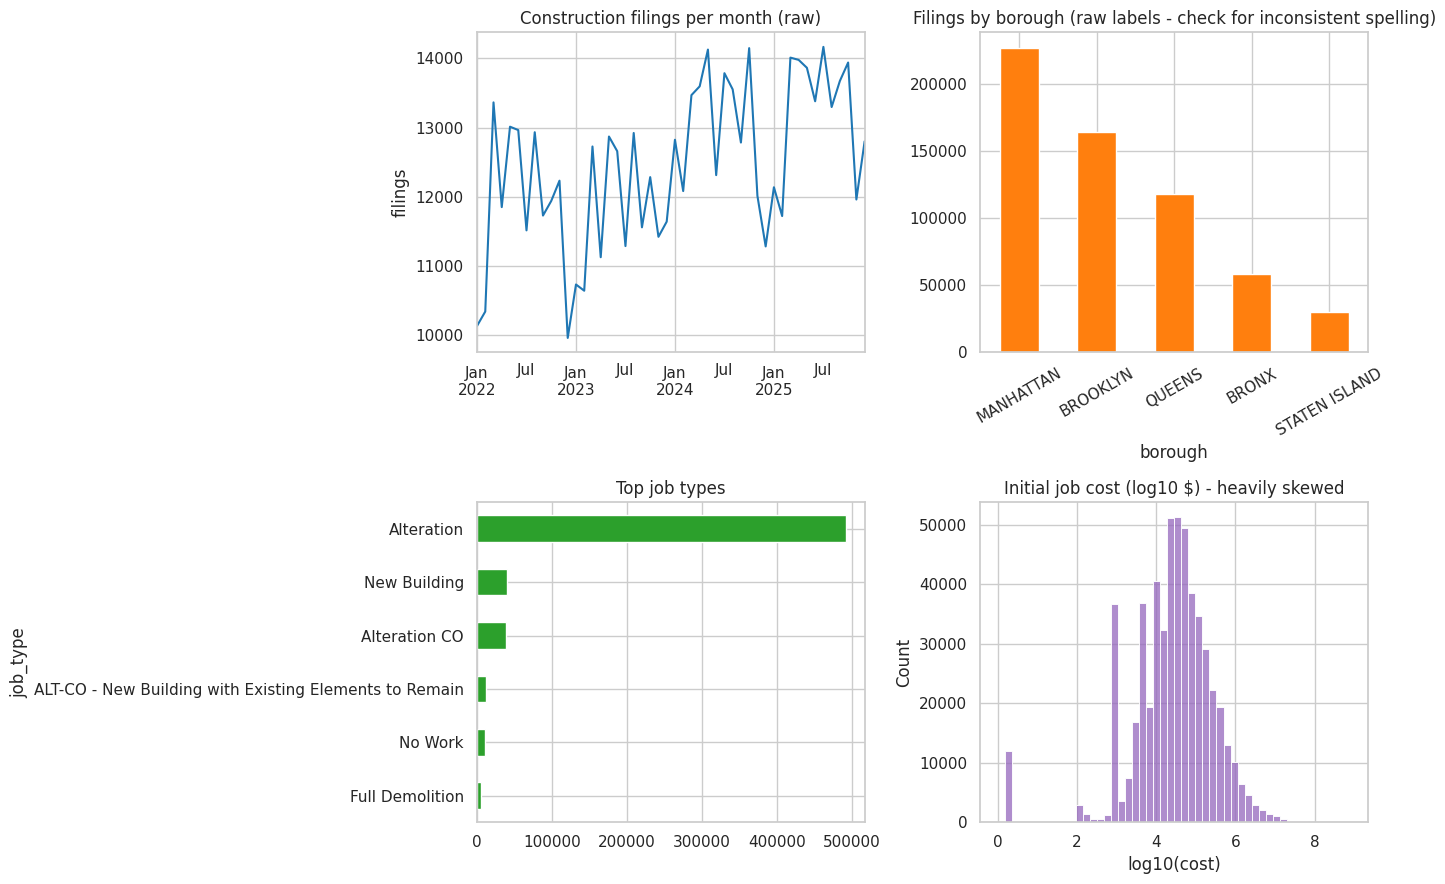

In [6]:
# Contributor: Tasneem  (housing EDA charts)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

h_std["date"].dt.to_period("M").value_counts().sort_index().plot(ax=axes[0, 0], color="#1f77b4")
axes[0, 0].set_title("Construction filings per month (raw)")
axes[0, 0].set_xlabel(""); axes[0, 0].set_ylabel("filings")

h_std["borough"].astype(str).str.upper().value_counts().plot.bar(ax=axes[0, 1], color="#ff7f0e")
axes[0, 1].set_title("Filings by borough (raw labels - check for inconsistent spelling)")
axes[0, 1].tick_params(axis="x", rotation=30)

h_std["job_type"].astype(str).value_counts().head(8).plot.barh(ax=axes[1, 0], color="#2ca02c")
axes[1, 0].set_title("Top job types"); axes[1, 0].invert_yaxis()

sns.histplot(np.log10(h_std["cost"].where(h_std["cost"] > 0).dropna() + 1), bins=50, ax=axes[1, 1], color="#9467bd")
axes[1, 1].set_title("Initial job cost (log10 $) - heavily skewed")
axes[1, 1].set_xlabel("log10(cost)")
plt.tight_layout(); plt.show()

**Housing EDA – what we noticed (and what we will fix):**
- Filing volume per month shows the pattern of construction activity over time; any odd spikes/drops are checked during cleaning.
- Borough labels can be inconsistent/missing → standardize to the 5 official boroughs.
- Costs and unit counts are extremely right-skewed with some implausible values → handle with domain rules + capping.
- Many job types (new building, alteration, demolition, …) → keep the main ones and group the rest as "Other".
- Some rows lack ZIP code and/or coordinates → try to recover ZIP from coordinates, drop rows with no location at all.

In [7]:
# Contributor: Sara  (crash EDA)
print("Crash column mapping:")
c_std = standardize(raw_crash, CRASH_COLS, required=["date", "borough"])
c_std["date"] = pd.to_datetime(c_std["date"], errors="coerce")
for col in ["injured", "killed", "ped_injured", "cyc_injured", "mot_injured", "latitude", "longitude"]:
    c_std[col] = pd.to_numeric(c_std[col], errors="coerce")

print("\nMissing values (% per standardised column):")
display((c_std.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("% missing"))
display(c_std[["injured", "killed", "ped_injured", "cyc_injured", "mot_injured"]].describe().T)

Crash column mapping:
  id              <- collision_id
  date            <- crash_date
  time            <- crash_time
  borough         <- borough
  zip_code        <- zip_code
  latitude        <- latitude
  longitude       <- longitude
  injured         <- number_of_persons_injured
  killed          <- number_of_persons_killed
  ped_injured     <- number_of_pedestrians_injured
  cyc_injured     <- number_of_cyclist_injured
  mot_injured     <- number_of_motorist_injured
  factor          <- contributing_factor_vehicle_1

Missing values (% per standardised column):


,% missing
zip_code,28.90
borough,26.30
latitude,6.40
longitude,6.40
factor,0.70
date,0.00
time,0.00
id,0.00
injured,0.00
killed,0.00


,count,mean,std,min,25%,50%,75%,max
injured,"377,371.00",0.56,0.85,0.00,0.00,0.00,1.00,40.00
killed,"377,371.00",0.00,0.06,0.00,0.00,0.00,0.00,5.00
ped_injured,"377,371.00",0.10,0.31,0.00,0.00,0.00,0.00,19.00
cyc_injured,"377,371.00",0.05,0.23,0.00,0.00,0.00,0.00,3.00
mot_injured,"377,371.00",0.38,0.82,0.00,0.00,0.00,0.00,40.00


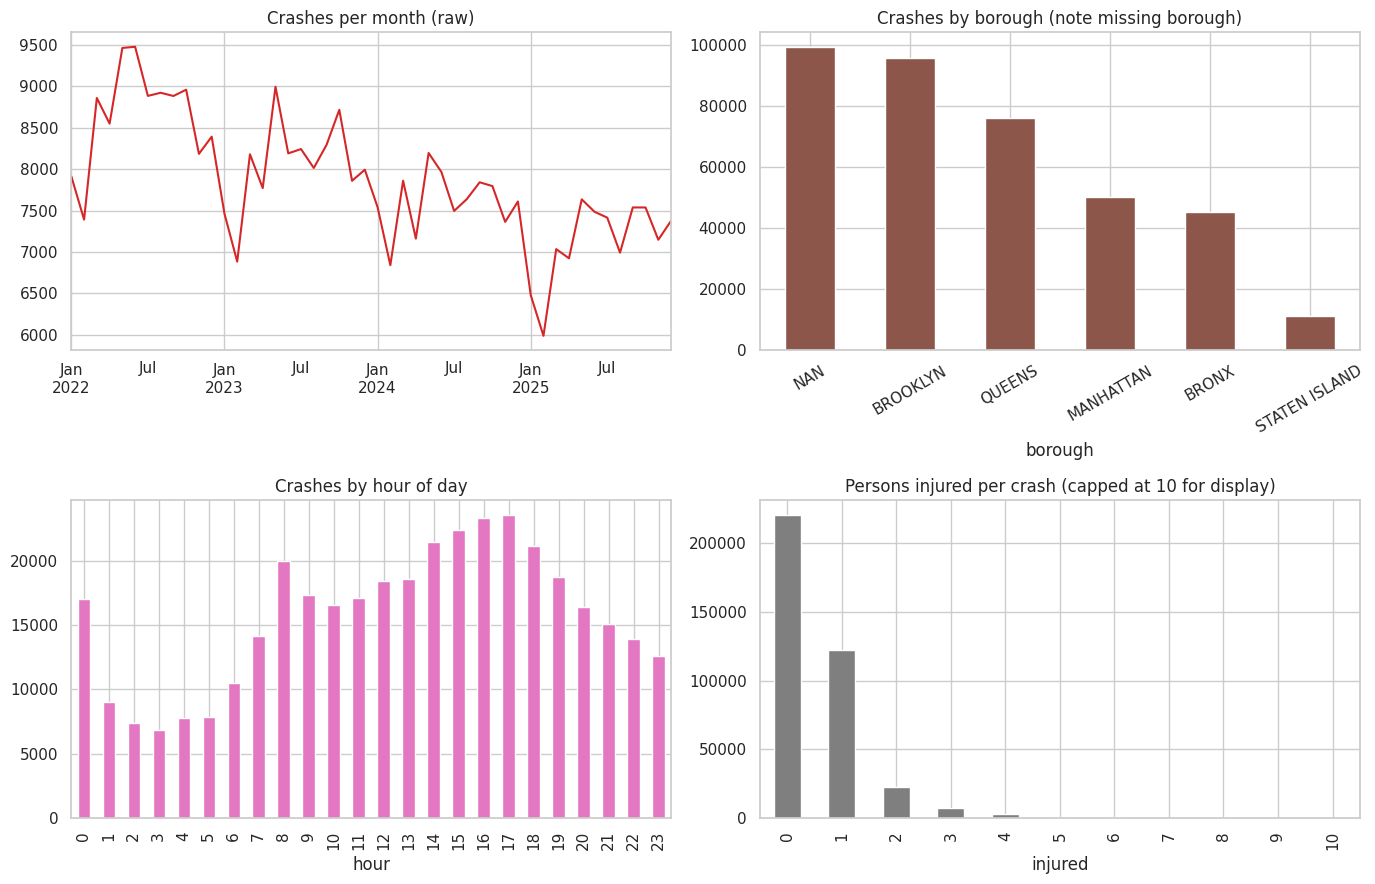

In [8]:
# Contributor: Sara  (crash EDA charts)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

c_std["date"].dt.to_period("M").value_counts().sort_index().plot(ax=axes[0, 0], color="#d62728")
axes[0, 0].set_title("Crashes per month (raw)"); axes[0, 0].set_xlabel("")

c_std["borough"].astype(str).str.upper().value_counts().plot.bar(ax=axes[0, 1], color="#8c564b")
axes[0, 1].set_title("Crashes by borough (note missing borough)"); axes[0, 1].tick_params(axis="x", rotation=30)

hours = pd.to_datetime(c_std["time"].astype(str), format="%H:%M", errors="coerce").dt.hour
hours.value_counts().sort_index().plot.bar(ax=axes[1, 0], color="#e377c2")
axes[1, 0].set_title("Crashes by hour of day"); axes[1, 0].set_xlabel("hour")

c_std["injured"].clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[1, 1], color="#7f7f7f")
axes[1, 1].set_title("Persons injured per crash (capped at 10 for display)")
plt.tight_layout(); plt.show()

**Crash EDA – what we noticed:**
- Most crashes injure nobody, so injury counts are zero-inflated; the IQR rule is not useful for them and we use **domain rules** instead.
- Borough and ZIP code are missing for a large share of crashes, but latitude/longitude is usually available → we can recover ZIP.
- Some coordinates are `0,0` or outside New York City → invalid and set to missing.
- The hourly profile shows the familiar rush-hour peaks, a good sanity check that the data is parsed correctly.

## 4. Pre-integration cleaning
Each table is cleaned separately. Every step is logged in a small table (rows before/after) so the effect of cleaning is visible.

Common helper functions are defined first (borough, ZIP, coordinate standardization).

In [9]:
# Contributor: Ziad  (shared cleaning helpers)
BOROUGH_FIX = {
    "MANHATTAN": "MANHATTAN", "MN": "MANHATTAN", "NEW YORK": "MANHATTAN", "1": "MANHATTAN",
    "BRONX": "BRONX", "THE BRONX": "BRONX", "BX": "BRONX", "2": "BRONX",
    "BROOKLYN": "BROOKLYN", "BK": "BROOKLYN", "KINGS": "BROOKLYN", "3": "BROOKLYN",
    "QUEENS": "QUEENS", "QN": "QUEENS", "4": "QUEENS",
    "STATEN ISLAND": "STATEN ISLAND", "SI": "STATEN ISLAND", "RICHMOND": "STATEN ISLAND", "5": "STATEN ISLAND",
}

def clean_borough(series):
    """Upper-case, trim and map spelling variants to the 5 boroughs. Anything else becomes NaN."""
    return series.astype(str).str.upper().str.strip().map(BOROUGH_FIX)

def clean_zip(series):
    """Keep the first 5 digits and accept only ZIPs in the NYC range 10000-11697."""
    z = pd.to_numeric(series.astype(str).str.extract(r"(\d{5})")[0], errors="coerce")
    return z.where((z >= 10000) & (z <= 11697))

def clean_latlon(lat, lon):
    """Coordinates outside the NYC bounding box (including 0,0) become NaN."""
    lat, lon = pd.to_numeric(lat, errors="coerce"), pd.to_numeric(lon, errors="coerce")
    inside = lat.between(40.45, 40.95) & lon.between(-74.30, -73.65)
    return lat.where(inside), lon.where(inside)

def log_step(log, step, before, after):
    """Record how many rows a cleaning step removed."""
    log.append({"step": step, "rows_before": before, "rows_after": after, "removed": before - after})

,step,rows_before,rows_after,removed
0,remove duplicate filings,598719,598664,55
1,drop missing/out-of-window dates,598664,598664,0
2,drop rows without ZIP or coordinates,598664,598278,386


IQR (log scale) upper fence = $4,700,064 -> 4,832 costs flagged as outliers
We cap cost at the 99th percentile ($4,050,651) instead of deleting rows: the filing is real, only the amount is extreme.


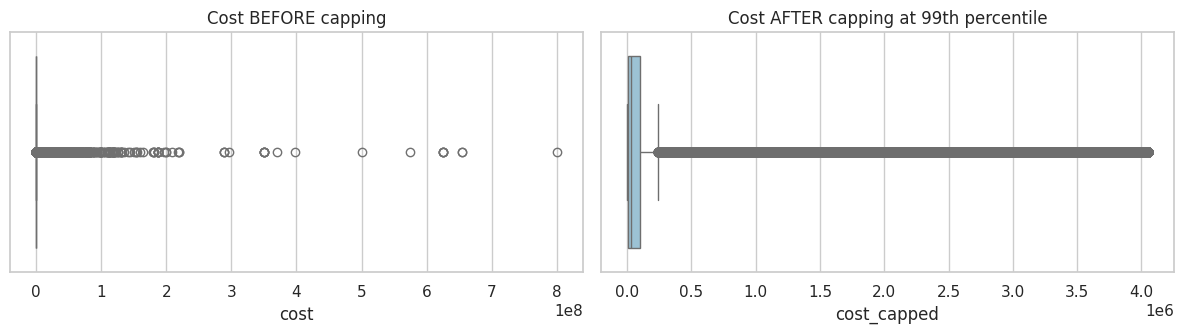

In [10]:
# Contributor: Ziad  (housing cleaning)
def clean_housing(h):
    log = []
    h = h.copy()

    # 1) Duplicates: a filing number must be unique
    before = len(h)
    h = h.drop_duplicates(subset="id") if h["id"].notna().any() else h.drop_duplicates()
    log_step(log, "remove duplicate filings", before, len(h))

    # 2) Dates: missing/invalid or outside the research window cannot be placed in time -> drop
    before = len(h)
    h = h[h["date"].between(pd.Timestamp(START_DATE), pd.Timestamp(END_DATE) + pd.Timedelta(days=1))]
    log_step(log, "drop missing/out-of-window dates", before, len(h))

    # 3) Standardize geography
    h["borough"] = clean_borough(h["borough"])
    h["zip_code"] = clean_zip(h["zip_code"])
    h["latitude"], h["longitude"] = clean_latlon(h["latitude"], h["longitude"])

    # 4) Rows with no usable location (no ZIP and no coordinates) cannot be integrated -> drop
    before = len(h)
    h = h[h["zip_code"].notna() | h["latitude"].notna()]
    log_step(log, "drop rows without ZIP or coordinates", before, len(h))

    # 5) Categories: job type
    h["job_type"] = h["job_type"].fillna("Unknown").astype(str).str.strip().str.title()
    h["is_new_building"] = h["job_type"].str.contains("new building", case=False, na=False).astype(int)

    # 6) Dwelling units: negative or > 5,000 units in one filing is implausible (domain rule) -> NaN
    for col in ["proposed_units", "existing_units"]:
        h[col] = h[col].where((h[col] >= 0) & (h[col] <= 5000))
    # Net NEW units = proposed - existing (never negative). Missing units mean "not applicable" (e.g. a sign job) -> 0.
    h["net_new_units"] = (h["proposed_units"].fillna(0) - h["existing_units"].fillna(0)).clip(lower=0)

    # 7) Cost: zero/negative is invalid -> NaN. Keep NaN (do NOT impute): imputing a cost for a job we know nothing about would invent data.
    h["cost"] = h["cost"].where(h["cost"] > 0)
    return h, pd.DataFrame(log)

housing, housing_log = clean_housing(h_std)
display(housing_log)

# Outlier handling for cost: IQR on log scale to DETECT, 99th-percentile cap to TREAT
log_cost = np.log1p(housing["cost"].dropna())
q1_, q3_ = log_cost.quantile([0.25, 0.75])
upper_fence = q3_ + 1.5 * (q3_ - q1_)
n_out = (log_cost > upper_fence).sum()
cap = housing["cost"].quantile(0.99)
print(f"IQR (log scale) upper fence = ${np.expm1(upper_fence):,.0f} -> {n_out:,} costs flagged as outliers")
print(f"We cap cost at the 99th percentile (${cap:,.0f}) instead of deleting rows: the filing is real, only the amount is extreme.")
housing["cost_capped"] = housing["cost"].clip(upper=cap)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=housing["cost"].dropna(), ax=ax[0], color="#f4a582"); ax[0].set_title("Cost BEFORE capping")
sns.boxplot(x=housing["cost_capped"].dropna(), ax=ax[1], color="#92c5de"); ax[1].set_title("Cost AFTER capping at 99th percentile")
plt.tight_layout(); plt.show()

**Housing cleaning decisions (justification):**
- **Duplicates** removed using the filing number (the natural unique key).
- **Dates** – rows without a valid date inside 2022–2025 are dropped; we cannot place them in a month, and they are a tiny share.
- **Location** – rows with neither ZIP nor coordinates are dropped (cannot be integrated). Rows with coordinates but no ZIP are **kept** and their ZIP is recovered in the integration step.
- **Cost** – missing/invalid costs stay missing (no imputation); sums ignore them. Extreme costs are **capped, not removed**.
- **Units** – implausible unit counts become missing; *net new units* treats "not applicable" as 0.
- **Alternatives considered:** imputing cost with the median per job type (rejected: would create fake spending), deleting all IQR outliers (rejected: would delete the largest and most interesting projects).

Fixed 0 crashes where total injured < sum of pedestrian+cyclist+motorist injured
IQR of injured = 1 (zero-inflated) -> IQR rule not meaningful; using domain cap of 30


,step,rows_before,rows_after,removed
0,remove duplicate crashes,377371,377371,0
1,drop missing/out-of-window dates,377371,377371,0
2,drop rows without ZIP or coordinates,377371,356815,20556


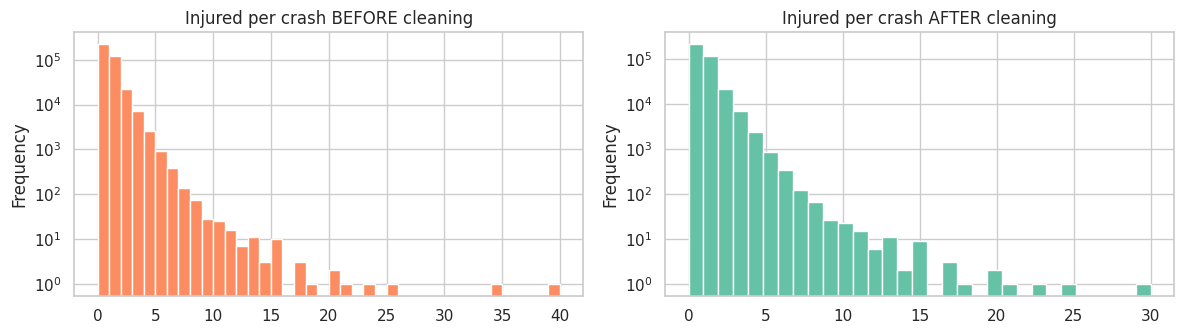

In [11]:
# Contributor: Sara  (crash cleaning)
def clean_crashes(c):
    log = []
    c = c.copy()

    # 1) Duplicates by collision id
    before = len(c)
    c = c.drop_duplicates(subset="id") if c["id"].notna().any() else c.drop_duplicates()
    log_step(log, "remove duplicate crashes", before, len(c))

    # 2) Dates inside the research window
    before = len(c)
    c = c[c["date"].between(pd.Timestamp(START_DATE), pd.Timestamp(END_DATE) + pd.Timedelta(days=1))]
    log_step(log, "drop missing/out-of-window dates", before, len(c))

    # 3) Standardise geography
    c["borough"] = clean_borough(c["borough"])
    c["zip_code"] = clean_zip(c["zip_code"])
    c["latitude"], c["longitude"] = clean_latlon(c["latitude"], c["longitude"])

    # 4) Rows with no usable location cannot be integrated -> drop
    before = len(c)
    c = c[c["zip_code"].notna() | c["latitude"].notna()]
    log_step(log, "drop rows without ZIP or coordinates", before, len(c))

    # 5) Injury/death counts: a missing count in this table means nobody was recorded -> 0
    for col in ["injured", "killed", "ped_injured", "cyc_injured", "mot_injured"]:
        c[col] = c[col].fillna(0).clip(lower=0)

    # 6) Inconsistency check: total injured must be at least the sum of its parts
    parts = c["ped_injured"] + c["cyc_injured"] + c["mot_injured"]
    n_inconsistent = (c["injured"] < parts).sum()
    c["injured"] = np.maximum(c["injured"], parts)
    print(f"Fixed {n_inconsistent:,} crashes where total injured < sum of pedestrian+cyclist+motorist injured")

    # 7) Outliers: IQR is useless for zero-inflated counts, so use a domain rule (> 30 injured in one crash is capped)
    q1_, q3_ = c["injured"].quantile([0.25, 0.75])
    print(f"IQR of injured = {q3_ - q1_:.0f} (zero-inflated) -> IQR rule not meaningful; using domain cap of 30")
    c["injured"] = c["injured"].clip(upper=30)
    c["ped_cyc_injured"] = c["ped_injured"] + c["cyc_injured"]

    # 8) Contributing factor: tidy text, missing -> 'Unspecified', keep top 8 categories, rest -> 'Other'
    c["factor"] = c["factor"].fillna("Unspecified").astype(str).str.strip().str.title()
    c.loc[c["factor"].isin(["", "Nan", "1", "80"]), "factor"] = "Unspecified"     # junk codes found in this column
    top_factors = c["factor"].value_counts().head(8).index
    c["factor_group"] = np.where(c["factor"].isin(top_factors), c["factor"], "Other")
    return c, pd.DataFrame(log)

crashes, crash_log = clean_crashes(c_std)
display(crash_log)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
c_std["injured"].clip(upper=40).plot.hist(bins=40, ax=ax[0], color="#fc8d62"); ax[0].set_title("Injured per crash BEFORE cleaning"); ax[0].set_yscale("log")
crashes["injured"].plot.hist(bins=31, ax=ax[1], color="#66c2a5"); ax[1].set_title("Injured per crash AFTER cleaning"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

**Crash cleaning decisions (justification):**
- Duplicates removed with `collision_id`; invalid coordinates (`0,0`, outside NYC) set to missing instead of dropping the crash.
- Missing injury counts → 0 (the data records people hurt; blank means none recorded). Inconsistent totals are corrected upward so they match the sum of their parts.
- Injury outliers are handled with a **domain cap**, because the IQR is zero for such skewed counts.
- Contributing factors are tidied and the long tail is grouped into "Other" so the website dropdown stays usable.
- **Not dropped:** crashes with coordinates but no ZIP — we recover the ZIP in section 5.

## 5. Integration

**Join key and granularity: ZIP code × year × month.**

| Option | Why we did / did not choose it |
|---|---|
| Row-level spatial join (each filing ↔ nearest crash) | ❌ Rejected: millions of pairs, arbitrary distance threshold, and the brief warns against joining rows just because a common attribute exists |
| Borough × month | ❌ Too coarse: only 5 areas, hides local patterns |
| Census tract | ❌ Needs extra shapefiles; many tracts have almost no events |
| **ZIP × month** | ✅ ~200 areas × 48 months, available in (or recoverable for) both datasets, readable for New Yorkers, and monthly counts are large enough to be meaningful |

**Steps:** (1) recover missing ZIPs from coordinates with a nearest-neighbour lookup, (2) make borough consistent with ZIP, (3) aggregate each dataset to ZIP × year × month (× category for the website filters), (4) outer-join the two aggregates.

In [12]:
# Contributor: Abdelrahman  (recover missing ZIPs from coordinates)
from sklearn.neighbors import BallTree

def fill_zip_by_nearest(df, reference, max_km=0.5):
    """Fill missing ZIPs using the nearest reference point that has a ZIP (haversine distance, max 500 m)."""
    df = df.copy()
    missing = df["zip_code"].isna() & df["latitude"].notna()
    if missing.sum() == 0 or reference.empty:
        return df
    tree = BallTree(np.radians(reference[["latitude", "longitude"]].values), metric="haversine")
    dist, idx = tree.query(np.radians(df.loc[missing, ["latitude", "longitude"]].values), k=1)
    km = dist[:, 0] * 6371.0
    found = reference["zip_code"].values[idx[:, 0]].astype(float)
    df.loc[missing, "zip_code"] = np.where(km <= max_km, found, np.nan)
    return df

# Reference = crash points that already have both a ZIP and coordinates (the biggest, densest set)
reference = crashes.dropna(subset=["zip_code", "latitude", "longitude"])[["zip_code", "latitude", "longitude"]]
print(f"Reference points: {len(reference):,}")

for name, frame in [("housing", housing), ("crashes", crashes)]:
    print(f"{name}: ZIP missing before = {frame['zip_code'].isna().sum():,}")
housing = fill_zip_by_nearest(housing, reference)
crashes = fill_zip_by_nearest(crashes, reference)
for name, frame in [("housing", housing), ("crashes", crashes)]:
    print(f"{name}: ZIP missing after  = {frame['zip_code'].isna().sum():,}")

# Rows that still have no ZIP cannot be placed in an area -> drop (and report)
for name in ["housing", "crashes"]:
    frame = globals()[name]
    before = len(frame)
    globals()[name] = frame[frame["zip_code"].notna()].copy()
    print(f"{name}: dropped {before - len(globals()[name]):,} rows with no ZIP after recovery")

Reference points: 260,252
housing: ZIP missing before = 130,868
crashes: ZIP missing before = 88,461
housing: ZIP missing after  = 1,510
crashes: ZIP missing after  = 5,346
housing: dropped 1,510 rows with no ZIP after recovery
crashes: dropped 5,346 rows with no ZIP after recovery


In [13]:
# Contributor: Abdelrahman  (consistent borough per ZIP, ZIP centroids)
# Each ZIP gets ONE borough (the most common label among all its rows), so both datasets use identical keys.
zip_borough = (pd.concat([housing[["zip_code", "borough"]], crashes[["zip_code", "borough"]]])
                 .dropna().groupby("zip_code")["borough"].agg(lambda s: s.mode().iat[0]))
housing["borough"] = housing["zip_code"].map(zip_borough)
crashes["borough"] = crashes["zip_code"].map(zip_borough)
housing = housing.dropna(subset=["borough"]).copy()
crashes = crashes.dropna(subset=["borough"]).copy()
housing["zip_code"] = housing["zip_code"].astype(int)
crashes["zip_code"] = crashes["zip_code"].astype(int)

# ZIP centroid (median coordinates of all points in that ZIP) - used for the maps
zip_centroids = (pd.concat([housing[["zip_code", "latitude", "longitude"]], crashes[["zip_code", "latitude", "longitude"]]])
                   .dropna().groupby("zip_code", as_index=False).median())
print(f"{zip_centroids.shape[0]} ZIP codes have a centroid | housing rows: {len(housing):,} | crash rows: {len(crashes):,}")

378 ZIP codes have a centroid | housing rows: 596,768 | crash rows: 351,469


In [14]:
# Contributor: Abdelrahman  (aggregate both datasets to ZIP x year x month)
# Housing job-type groups for the website dropdown: top 5 types, rest = Other
top_jobs = housing["job_type"].value_counts().head(5).index
housing["job_group"] = np.where(housing["job_type"].isin(top_jobs), housing["job_type"], "Other")
for frame in (housing, crashes):
    frame["year"] = frame["date"].dt.year
    frame["month"] = frame["date"].dt.month

keys = ["zip_code", "borough", "year", "month"]

housing_agg = (housing.groupby(keys + ["job_group"], as_index=False)
               .agg(filings=("id", "size"),                      # number of filings
                    new_building_filings=("is_new_building", "sum"),
                    new_units=("net_new_units", "sum"),           # net new dwelling units
                    total_cost=("cost_capped", "sum"))            # NaN costs are ignored in the sum
               .rename(columns={"job_group": "job_type"}))

crashes["injury_crash"] = (crashes["injured"] > 0).astype(int)
crash_agg = (crashes.groupby(keys + ["factor_group"], as_index=False)
             .agg(crashes=("id", "size"),
                  injury_crashes=("injury_crash", "sum"),
                  injured=("injured", "sum"),
                  killed=("killed", "sum"),
                  ped_cyc_injured=("ped_cyc_injured", "sum"))
             .rename(columns={"factor_group": "factor"}))

print("housing_agg:", housing_agg.shape, "| crash_agg:", crash_agg.shape)
display(housing_agg.head(3)); display(crash_agg.head(3))

housing_agg: (35459, 9) | crash_agg: (53529, 10)


,zip_code,borough,year,month,job_type,filings,new_building_filings,new_units,total_cost
0,10000,MANHATTAN,2022,1,Alteration,2,0,0.00,"89,700.00"
1,10000,MANHATTAN,2022,2,Alteration,2,0,0.00,"38,000.00"
2,10000,MANHATTAN,2022,3,Alteration,3,0,0.00,"354,999.86"


,zip_code,borough,year,month,factor,crashes,injury_crashes,injured,killed,ped_cyc_injured
0,10000,MANHATTAN,2022,1,Passing Or Lane Usage Improper,1,1,1,0,1
1,10000,MANHATTAN,2022,1,Unspecified,1,0,0,0,0
2,10000,MANHATTAN,2022,2,Driver Inattention/Distraction,1,1,2,0,0


In [15]:
# Contributor: Abdelrahman  (the join)
# Collapse the category columns first, then OUTER join on ZIP x year x month so months with only one kind of event are kept.
h_zm = housing_agg.groupby(keys, as_index=False)[["filings", "new_building_filings", "new_units", "total_cost"]].sum()
c_zm = crash_agg.groupby(keys, as_index=False)[["crashes", "injury_crashes", "injured", "killed", "ped_cyc_injured"]].sum()

panel_raw = h_zm.merge(c_zm, on=keys, how="outer", indicator=True)
print(panel_raw["_merge"].value_counts().rename({"both": "ZIP-months with filings AND crashes",
                                                 "left_only": "only filings",
                                                 "right_only": "only crashes"}))
print(f"\nPanel shape before post-integration cleaning: {panel_raw.shape}")
display(panel_raw.head())

_merge
ZIP-months with filings AND crashes    8585
only filings                           5842
only crashes                            264
Name: count, dtype: int64

Panel shape before post-integration cleaning: (14691, 14)


,zip_code,borough,year,month,filings,new_building_filings,new_units,total_cost,crashes,injury_crashes,injured,killed,ped_cyc_injured,_merge
0,10000,MANHATTAN,2022,1,2.00,0.00,0.00,"89,700.00",2.00,1.00,1.00,0.00,1.00,both
1,10000,MANHATTAN,2022,2,2.00,0.00,0.00,"38,000.00",1.00,1.00,2.00,0.00,0.00,both
2,10000,MANHATTAN,2022,3,3.00,0.00,0.00,"354,999.86",1.00,1.00,1.00,0.00,1.00,both
3,10000,MANHATTAN,2022,4,3.00,0.00,0.00,"36,000.00",1.00,1.00,1.00,0.00,0.00,both
4,10000,MANHATTAN,2022,5,NaN,NaN,NaN,NaN,3.00,3.00,3.00,0.00,2.00,right_only


## 6. Post-integration cleaning
After the outer join we must resolve: **new missing values from the join, inconsistent/redundant columns, and data-type mismatches.**

In [16]:
# Contributor: Yassin  (post-integration cleaning)
panel = panel_raw.copy()

# 1) NEW MISSING VALUES created by the join: a ZIP-month with no filings has NaN in the filing columns (and vice versa).
metric_cols = ["filings", "new_building_filings", "new_units", "total_cost",
               "crashes", "injury_crashes", "injured", "killed", "ped_cyc_injured"]
print("Missing values created by the join:")
display(panel[metric_cols].isna().sum().to_frame("NaN after join"))
# They mean "nothing happened that month", i.e. a real zero -> fill with 0 (not the mean/median: that would invent events)
panel[metric_cols] = panel[metric_cols].fillna(0)

# 2) REDUNDANT columns: drop the merge indicator
panel = panel.drop(columns=["_merge"])

# 3) DATA TYPE mismatches: counts are integers, key columns have fixed types, add a proper date column
int_cols = ["filings", "new_building_filings", "new_units", "crashes", "injury_crashes", "injured", "killed", "ped_cyc_injured"]
panel[int_cols] = panel[int_cols].round().astype(int)
panel[["zip_code", "year", "month"]] = panel[["zip_code", "year", "month"]].astype(int)
panel["borough"] = panel["borough"].astype("category")
panel["date"] = pd.to_datetime(dict(year=panel["year"], month=panel["month"], day=1))

# 4) INCONSISTENCIES: injury crashes can never exceed crashes; killed/injured can't be negative; no duplicate keys
assert (panel["injury_crashes"] <= panel["crashes"]).all(), "injury crashes > crashes"
assert (panel[["injured", "killed", "filings"]] >= 0).all().all(), "negative counts"
assert not panel.duplicated(subset=keys).any(), "duplicate ZIP-months"

# 5) RECONCILIATION: the join must not lose or create events
assert panel["filings"].sum() == housing_agg["filings"].sum(), "filings lost in join"
assert panel["crashes"].sum() == crash_agg["crashes"].sum(), "crashes lost in join"
print("\n✅ Checks passed: totals match the aggregated tables, no duplicate ZIP-months, no negative counts.")

# 6) New missing values from adding ZIP centroids (some ZIPs may have no coordinates) - kept for tables, dropped only on maps
missing_centroid = (~panel["zip_code"].isin(zip_centroids["zip_code"])).sum()
print(f"ZIP-months without a centroid: {missing_centroid:,} (they are simply not drawn on maps)")

panel.info()
display(panel.describe().T[["mean", "std", "min", "max"]])

Missing values created by the join:


,NaN after join
filings,264
new_building_filings,264
new_units,264
total_cost,264
crashes,5842
injury_crashes,5842
injured,5842
killed,5842
ped_cyc_injured,5842



✅ Checks passed: totals match the aggregated tables, no duplicate ZIP-months, no negative counts.
ZIP-months without a centroid: 0 (they are simply not drawn on maps)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14691 entries, 0 to 14690
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   zip_code              14691 non-null  int64         
 1   borough               14691 non-null  category      
 2   year                  14691 non-null  int64         
 3   month                 14691 non-null  int64         
 4   filings               14691 non-null  int64         
 5   new_building_filings  14691 non-null  int64         
 6   new_units             14691 non-null  int64         
 7   total_cost            14691 non-null  float64       
 8   crashes               14691 non-null  int64         
 9   injury_crashes        14691 non-null  int64         
 10  injured               

,mean,std,min,max
zip_code,"10,815.97",541.84,"10,000.00","11,697.00"
year,"2,023.50",1.12,"2,022.00","2,025.00"
month,6.50,3.44,1.00,12.00
filings,40.62,78.23,0.00,919.00
new_building_filings,3.57,10.00,0.00,330.00
new_units,222.37,786.75,0.00,"18,878.00"
total_cost,"6,911,283.64","20,233,463.32",0.00,"324,834,727.71"
crashes,23.92,28.60,0.00,211.00
injury_crashes,9.93,12.43,0.00,90.00
injured,13.21,17.02,0.00,130.00


In [17]:
# Contributor: Yassin  (save the small files the website needs)
housing_agg.to_csv("data/housing_agg.csv.gz", index=False)
crash_agg.to_csv("data/crash_agg.csv.gz", index=False)
zip_centroids.to_csv("data/zip_centroids.csv", index=False)
panel.to_csv("data/panel_zip_month.csv.gz", index=False)
for f in sorted(os.listdir("data")):
    print(f"{f:<28} {os.path.getsize('data/' + f) / 1e6:6.2f} MB")

crash_agg.csv.gz               0.28 MB
housing_agg.csv.gz             0.31 MB
panel_zip_month.csv.gz         0.23 MB
zip_centroids.csv              0.01 MB


## 7. Research questions and visualizations

**How this section works (kept simple).**
- Every research question has **one small function** called `chart_1`, `chart_2`, … `chart_12`. Each function takes two tables – `h` (the housing table) and `c` (the crash table) – and returns one Plotly chart.
- The website uses the **same functions**, but passes in tables that were filtered by the dropdowns. That is the only reason the functions take `h` and `c` instead of using the full tables directly.
- Each function cell starts with `%%writefile -a charts.py`, which saves the code into a file called `charts.py` (the website imports that file). The notebook then imports `charts` and draws every chart in section 7.2.
- **Run the cells in order.** If you need to re-run section 7.1, run the first cell (`%%writefile charts.py`) again first so the file starts clean.

The 12 questions mix **spatial** questions (boroughs, ZIP codes, a ZIP-code hotspot chart), **time-based** questions (trends, seasons, delays), and **correlation / prediction** questions (scatter plots and a yes/no model).

### 7.1 The chart functions

In [18]:
%%writefile charts.py
"""charts.py - the 12 chart functions used by the notebook AND the website.
Every chart_N(h, c) gets the housing table h and the crash table c and returns a Plotly figure."""
import os
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ZIP centroids (ZIP locations) are only needed for the hotspot chart (Q2)
HERE = os.path.dirname(os.path.abspath(__file__))
ZIP_CENTROIDS = pd.read_csv(os.path.join(HERE, "data", "zip_centroids.csv"))

KEYS = ["zip_code", "borough", "year", "month"]
H_NUMBERS = ["filings", "new_building_filings", "new_units", "total_cost"]
C_NUMBERS = ["crashes", "injury_crashes", "injured", "killed", "ped_cyc_injured"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def no_data(message="No data for the selected filters"):
    """An empty chart with a message (shown when the filters leave nothing to draw)."""
    fig = go.Figure()
    fig.add_annotation(text=message, x=0.5, y=0.5, xref="paper", yref="paper", showarrow=False, font=dict(size=16))
    fig.update_layout(xaxis_visible=False, yaxis_visible=False, height=420)
    return fig


def join_data(h, c):
    """One row per ZIP x year x month with housing AND crash numbers (the same join as sections 5-6)."""
    h_month = h.groupby(KEYS, as_index=False)[H_NUMBERS].sum()
    c_month = c.groupby(KEYS, as_index=False)[C_NUMBERS].sum()
    return h_month.merge(c_month, on=KEYS, how="outer").fillna(0)


def zip_table(joined):
    """One row per ZIP code (totals for the selected period)."""
    z = joined.groupby(["zip_code", "borough"], as_index=False)[H_NUMBERS + C_NUMBERS].sum()
    z["zip_label"] = z["zip_code"].astype(int).astype(str)
    return z


def add_trend_line(fig, x, y):
    """Draw a straight best-fit line on a scatter plot and return the correlation r."""
    ok = x.notna() & y.notna()
    if ok.sum() < 3 or x[ok].nunique() < 2:
        return None
    slope, intercept = np.polyfit(x[ok], y[ok], 1)
    xs = np.linspace(x[ok].min(), x[ok].max(), 50)
    fig.add_trace(go.Scatter(x=xs, y=slope * xs + intercept, mode="lines", name="Best-fit line", line=dict(color="black", dash="dash")))
    return float(np.corrcoef(x[ok], y[ok])[0, 1])


def show_r(r):
    return "n/a" if r is None or pd.isna(r) else f"{r:.2f}"


def key_findings(h, c):
    """A few plain-English findings calculated from the data on screen (used in the notebook story and on the website)."""
    joined = join_data(h, c)
    if joined.empty:
        return ["No data for the selected filters."]
    z = zip_table(joined)
    lines = [f"**{int(z['filings'].sum()):,}** construction filings and **{int(z['crashes'].sum()):,}** crashes "
             f"({int(z['injured'].sum()):,} people injured, {int(z['killed'].sum()):,} killed) in **{len(z)}** ZIP codes."]
    b = z.groupby("borough")[["filings", "crashes"]].sum()
    b = b[b["filings"] > 0]
    if not b.empty:
        ratio = (b["crashes"] / b["filings"] * 100).sort_values(ascending=False)
        lines.append(f"**{ratio.index[0].title()}** has the most crashes per 100 filings ({ratio.iloc[0]:,.0f}) and "
                     f"**{ratio.index[-1].title()}** the fewest ({ratio.iloc[-1]:,.0f}).")
    if len(z) >= 5:
        rho = z["filings"].corr(z["crashes"], method="spearman")
        lines.append(f"Across ZIP codes, filings and crashes have a rank correlation of **{show_r(rho)}**. "
                     "Big, busy ZIP codes tend to have both, so this does **not** show that construction causes crashes.")
    return lines

Writing charts.py


### Q1 (Tasneem) – Does each borough's share of new housing match its share of people injured in crashes?
**Type:** spatial comparison. **Why it matters:** if a borough receives, say, 40% of the new homes but has 20% of the injuries (or the reverse), the city can see where growth and street danger are out of balance.
**Chart choice:** a **grouped bar chart** – two bars per borough, both measured in "% of the city total", so they are directly comparable even though units and injuries are very different numbers.

In [19]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q1  (Tasneem)
def chart_1(h, c):
    joined = join_data(h, c)
    b = joined.groupby("borough", as_index=False)[["new_units", "injured"]].sum()
    if b["new_units"].sum() == 0 or b["injured"].sum() == 0:
        return no_data("Not enough new-unit and injury data for these filters")
    # turn each borough's numbers into a share of the city total
    b["Share of new housing units (%)"] = b["new_units"] / b["new_units"].sum() * 100
    b["Share of people injured (%)"] = b["injured"] / b["injured"].sum() * 100
    long = b.melt(id_vars="borough", value_vars=["Share of new housing units (%)", "Share of people injured (%)"],
                  var_name="measure", value_name="share")
    return px.bar(long, x="borough", y="share", color="measure", barmode="group", text_auto=".0f",
                  labels={"share": "% of city total", "borough": "Borough", "measure": ""},
                  title="Q1 - Each borough's share of new housing units vs share of people injured")

Appending to charts.py


### Q2 (Tasneem) – Which ZIP codes are hotspots for both construction and crashes, and where are they?
**Type:** spatial – **the required chart that shows both domains together.** **Why it matters:** planners and safety teams need to know whether the places with the most construction are also the places with the most crashes, or whether those are different parts of the city.
**Method:** each ZIP code is placed at its location (longitude/latitude of its centre). A ZIP is "high construction" if it is in the top 25% of ZIP codes for filings, and "high crashes" if it is in the top 25% for crashes. ZIP codes in **both** groups are the hotspots.
**Chart choice:** a **location bubble chart** – each bubble is one ZIP code placed by its position (borough names are added to help you find your way), **bubble size = crashes**, **colour = group** (hotspot, high construction only, high crashes only, everything else). We do not use a street map because the free map tiles are blocked in some places (including Colab), which broke the first version; this chart needs no outside map files, so it always works. Hover to see the ZIP code and numbers.

In [20]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q2  (Tasneem)
def chart_2(h, c):
    z = zip_table(join_data(h, c))
    z = z.merge(ZIP_CENTROIDS, on="zip_code", how="left").dropna(subset=["latitude", "longitude"])   # ZIPs without a location are not drawn
    z = z[(z["filings"] > 0) | (z["crashes"] > 0)].copy()
    if len(z) < 8:
        return no_data("Need at least 8 ZIP codes")
    # "high" = in the top 25% of ZIP codes for that measure
    high_construction = z["filings"] >= z["filings"].quantile(0.75)
    high_crashes = z["crashes"] >= z["crashes"].quantile(0.75)
    hotspot, only_construction, only_crashes, rest = ("Hotspot: high construction AND high crashes", "High construction only",
                                                      "High crashes only", "Everything else")
    z["group"] = np.select([high_construction & high_crashes, high_construction, high_crashes],
                           [hotspot, only_construction, only_crashes], default=rest)
    fig = px.scatter(z, x="longitude", y="latitude", color="group", size="crashes", size_max=26, opacity=0.75,
                     color_discrete_map={hotspot: "#d62728", only_construction: "#1f77b4", only_crashes: "#ff7f0e", rest: "#c8c8c8"},
                     category_orders={"group": [hotspot, only_construction, only_crashes, rest]},
                     hover_name="zip_label", hover_data={"borough": True, "filings": ":,", "crashes": ":,", "longitude": False, "latitude": False},
                     labels={"group": ""}, height=620,
                     title="Q2 - ZIP-code hotspots: bubble size = crashes, colour = construction/crash group")
    # borough names at the average position of their ZIP codes, to help the reader find their way
    names = z.groupby("borough")[["longitude", "latitude"]].mean().reset_index()
    fig.add_trace(go.Scatter(x=names["longitude"], y=names["latitude"], text=names["borough"].str.title(), mode="text",
                             textfont=dict(size=13, color="black"), showlegend=False, hoverinfo="skip"))
    # keep the shape of the city right: 1 degree of latitude is about 1.32x longer than 1 degree of longitude here
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False, scaleanchor="x", scaleratio=1 / np.cos(np.radians(40.7)))
    return fig

Appending to charts.py


### Q3 (Sara) – Do monthly construction filings and monthly crashes move together over time?
**Type:** time-based. **Why it matters:** if both rise and fall together (for example with the seasons), that must be kept in mind before blaming one on the other.
**Chart choice:** a **line chart** (the standard choice for trends over time). Filings and crashes have very different sizes, so each line is shown as an **index (its own average = 100)**. The title reports the correlation between the two monthly series.

In [21]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q3  (Sara)
def chart_3(h, c):
    joined = join_data(h, c)
    monthly = joined.groupby(["year", "month"], as_index=False)[["filings", "crashes"]].sum()
    if len(monthly) < 3:
        return no_data("Need at least 3 months of data")
    monthly["date"] = pd.to_datetime(dict(year=monthly["year"].astype(int), month=monthly["month"].astype(int), day=1))
    monthly = monthly.sort_values("date")
    # index each series to its own average (= 100) so both fit on one axis
    monthly["Construction filings"] = monthly["filings"] / (monthly["filings"].mean() or np.nan) * 100
    monthly["Crashes"] = monthly["crashes"] / (monthly["crashes"].mean() or np.nan) * 100
    long = monthly.melt(id_vars="date", value_vars=["Construction filings", "Crashes"], var_name="measure", value_name="index")
    r = monthly["filings"].corr(monthly["crashes"])
    return px.line(long, x="date", y="index", color="measure", markers=True,
                   labels={"index": "Index (own average = 100)", "date": "Month", "measure": ""},
                   title=f"Q3 - Monthly construction filings vs crashes (correlation r = {show_r(r)})")

Appending to charts.py


### Q4 (Sara) – Which months of the year are busiest for filings and for injury crashes?
**Type:** time-based (seasonality). **Why it matters:** knowing the busy months helps inspectors and safety campaigns plan.
**Chart choice:** two side-by-side **heatmaps** (years down, months across). A heatmap shows seasons *and* year-to-year change in one small picture; a line chart with 48 points would be harder to read.

In [22]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q4  (Sara)
def chart_4(h, c):
    joined = join_data(h, c)
    if joined.empty:
        return no_data()
    fig = make_subplots(rows=1, cols=2, subplot_titles=("Construction filings", "Crashes with injuries"), horizontal_spacing=0.14)
    for position, (column, colours) in enumerate([("filings", "Blues"), ("injury_crashes", "Reds")], start=1):
        table = joined.pivot_table(index="year", columns="month", values=column, aggfunc="sum").reindex(columns=range(1, 13))
        fig.add_trace(go.Heatmap(z=table.values, x=MONTH_NAMES, y=[str(y) for y in table.index], colorscale=colours,
                                 colorbar=dict(x=0.43 if position == 1 else 1.02, len=0.9),
                                 hovertemplate="%{y} %{x}: %{z:,.0f}<extra></extra>"), row=1, col=position)
    fig.update_yaxes(type="category")
    fig.update_layout(title="Q4 - Busiest months: filings (left) and injury crashes (right)")
    return fig

Appending to charts.py


### Q5 (Ziad) – Do ZIP codes with more new housing units also have more crashes?
**Type:** correlation. **Why it matters:** new homes bring residents and traffic; this is the most direct version of the "new development vs safety" question.
**Chart choice:** a **scatter plot** (one dot per ZIP code) with a dashed best-fit line, coloured by borough. A scatter plot is the standard way to show how two numbers move together. The title gives Pearson r and Spearman (Spearman is less affected by a few extreme ZIPs).

In [23]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q5  (Ziad)
def chart_5(h, c):
    z = zip_table(join_data(h, c))
    z = z[(z["crashes"] > 0) | (z["new_units"] > 0)]
    if len(z) < 3:
        return no_data()
    fig = px.scatter(z, x="new_units", y="crashes", color="borough", hover_name="zip_label",
                     hover_data={"filings": ":,", "new_units": ":,", "crashes": ":,"},
                     labels={"new_units": "Net new dwelling units filed", "crashes": "Crashes"})
    r = add_trend_line(fig, z["new_units"], z["crashes"])
    rho = z["new_units"].corr(z["crashes"], method="spearman")
    fig.update_layout(title=f"Q5 - New housing units vs crashes per ZIP (r = {show_r(r)}, Spearman = {show_r(rho)})")
    return fig

Appending to charts.py


### Q6 (Ziad) – Are crashes more severe in ZIP codes with more construction?
**Type:** spatial / group comparison. **Why it matters:** the *number* of crashes and how *severe* they are can tell different stories.
**Chart choice:** a **box plot** of "people injured per 100 crashes". ZIP codes are put into four equal groups by their number of construction filings, and the box plot compares those groups (middle, spread and outliers, not just an average). ZIP codes with fewer than 10 crashes are left out because their ratio is unreliable.

In [24]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q6  (Ziad)
def chart_6(h, c):
    z = zip_table(join_data(h, c))
    z = z[z["crashes"] >= 10].copy()
    if len(z) < 8:
        return no_data("Need at least 8 ZIP codes with 10 or more crashes")
    z["injured_per_100_crashes"] = z["injured"] / z["crashes"] * 100
    # four equal groups of ZIP codes, from least to most construction
    z["construction_level"] = pd.qcut(z["filings"].rank(method="first"), 4, labels=["1 (lowest)", "2", "3", "4 (highest)"])
    fig = px.box(z, x="construction_level", y="injured_per_100_crashes", color="construction_level", points="all",
                 hover_name="zip_label", hover_data={"borough": True, "filings": ":,", "construction_level": False},
                 labels={"construction_level": "Construction filings (ZIP group)", "injured_per_100_crashes": "People injured per 100 crashes"},
                 title="Q6 - Are crashes more severe in ZIP codes with more construction?")
    fig.update_layout(showlegend=False)
    return fig

Appending to charts.py


### Q7 (Abdelrahman) – Do crashes rise in the months after a spike in construction filings?
**Type:** time-based (delay). **Why it matters:** if construction affected safety, the effect might show up a few months later rather than in the same month.
**Method:** for the whole city, we compare each month's filings with the crashes **0, 1, 2 … 6 months later** (using `shift`).
**Chart choice:** a **bar chart of correlation by delay**. Bars near zero mean no consistent delayed link; tall bars mean filings and later crashes move together.

In [25]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q7  (Abdelrahman)
def chart_7(h, c):
    joined = join_data(h, c)
    monthly = joined.groupby(["year", "month"], as_index=False)[["filings", "crashes"]].sum()
    if len(monthly) < 10:
        return no_data("Need at least 10 months of data")
    monthly["date"] = pd.to_datetime(dict(year=monthly["year"].astype(int), month=monthly["month"].astype(int), day=1))
    monthly = monthly.set_index("date").sort_index().asfreq("MS", fill_value=0)       # one row for every month
    rows = []
    for delay in range(0, 7):
        # shift(-delay) moves the crash numbers `delay` months earlier, so each row pairs filings with LATER crashes
        rows.append({"months_later": delay, "correlation": monthly["filings"].corr(monthly["crashes"].shift(-delay))})
    result = pd.DataFrame(rows)
    fig = px.bar(result, x="months_later", y="correlation", text_auto=".2f",
                 labels={"months_later": "Crashes measured this many months after the filings", "correlation": "Correlation"},
                 title="Q7 - Do crashes follow construction filings? (citywide monthly correlation by delay)")
    fig.update_xaxes(dtick=1)
    return fig

Appending to charts.py


### Q8 (Abdelrahman) – Which types of construction jobs are filed in the most crash-prone ZIP codes?
**Type:** categorical. **Why it matters:** new buildings, alterations and demolitions happen in different kinds of places.
**Method:** for every filing we look up how many crashes happened in the same ZIP code and year, then average that number for each job type.
**Chart choice:** a **horizontal bar chart** (category names are long, so they read better sideways), sorted so the highest is on top.

In [26]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q8  (Abdelrahman)
def chart_8(h, c):
    if h.empty or c.empty:
        return no_data()
    filings = h.groupby(["zip_code", "year", "job_type"], as_index=False)["filings"].sum()
    crashes = c.groupby(["zip_code", "year"], as_index=False)["crashes"].sum()
    both = filings.merge(crashes, on=["zip_code", "year"], how="left").fillna({"crashes": 0})
    # average crashes per filing of each job type (a ZIP-year with more filings counts more)
    both["crashes_x_filings"] = both["crashes"] * both["filings"]
    result = both.groupby("job_type", as_index=False)[["crashes_x_filings", "filings"]].sum()
    result["avg_crashes"] = result["crashes_x_filings"] / result["filings"]
    result = result.sort_values("avg_crashes")
    return px.bar(result, x="avg_crashes", y="job_type", orientation="h", text_auto=".0f", hover_data={"filings": ":,"},
                  labels={"avg_crashes": "Average crashes in the same ZIP and year", "job_type": "Job type"},
                  title="Q8 - Which kinds of jobs are filed in the most crash-prone ZIP codes?")

Appending to charts.py


### Q9 (Yassin) – Which ZIP codes have the most pedestrian and cyclist injuries, and how much construction do they have?
**Type:** spatial ranking. **Why it matters:** pedestrians and cyclists are the most vulnerable road users, and construction often blocks sidewalks and bike lanes.
**Chart choice:** a **ranked bar chart** of the top 15 ZIP codes. The bar **colour = construction filings**, so a second variable is visible without cluttering the chart.

In [27]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q9  (Yassin)
def chart_9(h, c):
    z = zip_table(join_data(h, c))
    z = z[z["ped_cyc_injured"] > 0].nlargest(15, "ped_cyc_injured")
    if z.empty:
        return no_data()
    fig = px.bar(z, x="zip_label", y="ped_cyc_injured", color="filings", color_continuous_scale="Viridis",
                 hover_data={"borough": True, "crashes": ":,", "filings": ":,", "zip_label": False},
                 labels={"zip_label": "ZIP code", "ped_cyc_injured": "Pedestrians + cyclists injured", "filings": "Construction filings"},
                 title="Q9 - Top 15 ZIP codes for pedestrian and cyclist injuries (colour = construction filings)")
    fig.update_xaxes(type="category")
    return fig

Appending to charts.py


### Q10 (Yassin) – Do ZIP codes with bigger (costlier) construction projects have more severe crashes?
**Type:** correlation. **Why it matters:** big projects mean heavy equipment and long disruptions.
**Chart choice:** a **bubble scatter plot**. x = average project cost per filing (**log scale**, because costs range from thousands to millions of dollars), y = people injured per 100 crashes, bubble size = number of crashes (so ZIPs with more data stand out), colour = borough. ZIP codes with fewer than 5 filings or 10 crashes are left out.

In [28]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q10  (Yassin)
def chart_10(h, c):
    z = zip_table(join_data(h, c))
    z = z[(z["filings"] >= 5) & (z["crashes"] >= 10)].copy()
    z["avg_cost_per_filing"] = z["total_cost"] / z["filings"]
    z["injured_per_100_crashes"] = z["injured"] / z["crashes"] * 100
    z = z[z["avg_cost_per_filing"] > 0]
    if len(z) < 3:
        return no_data("Need ZIP codes with 5+ filings and 10+ crashes")
    rho = z["avg_cost_per_filing"].corr(z["injured_per_100_crashes"], method="spearman")
    return px.scatter(z, x="avg_cost_per_filing", y="injured_per_100_crashes", size="crashes", color="borough", log_x=True,
                      hover_name="zip_label", size_max=30, hover_data={"filings": ":,", "crashes": ":,"},
                      labels={"avg_cost_per_filing": "Average project cost per filing ($, log scale)",
                              "injured_per_100_crashes": "People injured per 100 crashes"},
                      title=f"Q10 - Project size vs crash severity (Spearman = {show_r(rho)})")

Appending to charts.py


### Q11 (Youssef) – Can a month's construction filings predict whether a ZIP code has an injury crash that month? (yes/no model)
**Type:** predictive. **Why it matters:** if construction activity helps predict injury crashes, it could be used as an early-warning signal; if not, that is also a useful result.
**Method (simple):**
1. Build one row for **every ZIP code in every month** (including months where nothing happened).
2. **Target (yes/no):** was there at least one crash with an injury in that ZIP that month?
3. **Inputs:** that month's number of filings, new-building filings and new housing units (log-scaled, then standardised).
4. **Logistic regression** (the yes/no version of regression) trained with gradient descent in plain NumPy on 80% of the rows, then tested on the other 20%.
5. Compare the test **accuracy** with a **baseline** that always guesses the most common answer. A useful model must beat the baseline.

**Chart choice:** a **grouped bar chart** that compares, for groups of ZIP-months with 0, 1, 2–3, 4–6 and 7+ filings, the *actual* share with an injury crash and the share the *model predicted*. If the bars are close, the model matches reality.
**Careful:** ZIP codes that file more jobs are usually bigger and busier, so a good score does **not** mean construction causes crashes.

In [29]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q11  (Youssef)
def train_logistic(X, y, steps=500, learning_rate=0.1):
    """Logistic regression with gradient descent. Returns weights w and bias b."""
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(steps):
        p = 1 / (1 + np.exp(-(X @ w + b)))                 # predicted probability of "yes"
        w -= learning_rate * (X.T @ (p - y)) / len(y)      # move the weights downhill
        b -= learning_rate * (p - y).mean()
    return w, b


def chart_11(h, c):
    joined = join_data(h, c)
    if joined.empty:
        return no_data()
    joined["date"] = pd.to_datetime(dict(year=joined["year"].astype(int), month=joined["month"].astype(int), day=1))
    # 1) one row for every ZIP in every month (months with no events become zeros)
    grid = pd.MultiIndex.from_product([joined["zip_code"].unique(), pd.date_range(joined["date"].min(), joined["date"].max(), freq="MS")],
                                      names=["zip_code", "date"]).to_frame(index=False)
    monthly = joined.groupby(["zip_code", "date"], as_index=False)[["filings", "new_building_filings", "new_units", "injury_crashes"]].sum()
    data = grid.merge(monthly, on=["zip_code", "date"], how="left").fillna(0)
    # 2) target and inputs
    y = (data["injury_crashes"] > 0).astype(float).values
    if len(data) < 200 or y.min() == y.max():
        return no_data("Need more months/ZIP codes (and both yes and no cases) for the model")
    X = np.log1p(data[["filings", "new_building_filings", "new_units"]].values)
    X = (X - X.mean(axis=0)) / np.where(X.std(axis=0) == 0, 1, X.std(axis=0))
    # 3) 80% train / 20% test (fixed seed so the result is repeatable)
    order = np.random.default_rng(42).permutation(len(data))
    cut = int(0.8 * len(data))
    train, test = order[:cut], order[cut:]
    w, b = train_logistic(X[train], y[train])
    probability = 1 / (1 + np.exp(-(X[test] @ w + b)))
    accuracy = ((probability > 0.5) == (y[test] == 1)).mean()
    baseline = max(y[test].mean(), 1 - y[test].mean())
    # 4) compare actual vs predicted share by number of filings
    result = pd.DataFrame({"filings": data["filings"].values[test], "actual": y[test], "predicted": probability})
    result["filings_group"] = pd.cut(result["filings"], [-1, 0, 1, 3, 6, np.inf], labels=["0", "1", "2-3", "4-6", "7+"])
    summary = result.groupby("filings_group", observed=True)[["actual", "predicted"]].mean() * 100
    long = summary.reset_index().melt(id_vars="filings_group", var_name="what", value_name="share")
    long["what"] = long["what"].map({"actual": "Actual share with an injury crash", "predicted": "Model's predicted share"})
    return px.bar(long, x="filings_group", y="share", color="what", barmode="group", text_auto=".0f",
                  labels={"filings_group": "Construction filings in the ZIP that month", "share": "% of ZIP-months", "what": ""},
                  title=f"Q11 - Predicting an injury crash from filings: accuracy {accuracy:.0%} vs {baseline:.0%} for always guessing the common answer")

Appending to charts.py


### Q12 (Youssef) – Are the main crash causes different in high-construction and low-construction ZIP codes?
**Type:** spatial / categorical. **Why it matters:** it is not only *how many* crashes happen but *why*. If construction areas have more distraction or following-too-closely crashes, for example, the safety response should be different.
**Method:** ZIP codes with more filings than the median ZIP are "high-construction", the rest "low-construction". For each group we calculate the **share of its crashes** that have each contributing factor ("Unspecified", "Other" and "Does Not Apply" are not shown, but they are still counted in the totals so shares stay honest).
**Chart choice:** a **grouped bar chart** – two bars (high vs low) for each cause, using shares so the groups can be compared even though they have different numbers of crashes.

In [30]:
%%writefile -a charts.py


# ---------------------------------------------------------------- Q12  (Youssef)
def chart_12(h, c):
    z = zip_table(join_data(h, c))
    z = z[(z["filings"] > 0) | (z["crashes"] > 0)]
    if len(z) < 8:
        return no_data("Need at least 8 ZIP codes")
    # label each ZIP: more filings than the median ZIP = high construction
    z["group"] = np.where(z["filings"] > z["filings"].median(), "High-construction ZIPs", "Low-construction ZIPs")
    c = c.copy()
    c["group"] = c["zip_code"].map(z.set_index("zip_code")["group"])
    by_cause = c.dropna(subset=["group"]).groupby(["group", "factor"], as_index=False)["crashes"].sum()
    by_cause["share"] = by_cause["crashes"] / by_cause.groupby("group")["crashes"].transform("sum") * 100
    by_cause = by_cause[~by_cause["factor"].isin(["Unspecified", "Other", "Does Not Apply"])]
    top_causes = by_cause.groupby("factor")["crashes"].sum().nlargest(6).index
    by_cause = by_cause[by_cause["factor"].isin(top_causes)]
    if by_cause.empty:
        return no_data()
    return px.bar(by_cause, x="factor", y="share", color="group", barmode="group", text_auto=".1f",
                  labels={"factor": "Contributing factor (vehicle 1)", "share": "% of the group's crashes", "group": ""},
                  title="Q12 - Main crash causes in high- vs low-construction ZIP codes")

Appending to charts.py


### 7.2 The 12 charts
Now we import `charts.py` and draw each chart with the full 2022–2025 data. Hover, zoom and pan on each chart.

In [31]:
# Contributor: Youssef  (import the charts file; H and C are the two tables from section 5)
import charts
H, C = housing_agg, crash_agg
print("Housing table:", H.shape, "| Crash table:", C.shape)

Housing table: (35459, 9) | Crash table: (53529, 10)


In [32]:
# Contributor: Tasneem  (Q1)
charts.chart_1(H, C).show()

In [33]:
# Contributor: Tasneem  (Q2)
charts.chart_2(H, C).show()

In [34]:
# Contributor: Sara  (Q3)
charts.chart_3(H, C).show()

In [35]:
# Contributor: Sara  (Q4)
charts.chart_4(H, C).show()

In [36]:
# Contributor: Ziad  (Q5)
charts.chart_5(H, C).show()

In [37]:
# Contributor: Ziad  (Q6)
charts.chart_6(H, C).show()

In [38]:
# Contributor: Abdelrahman  (Q7)
charts.chart_7(H, C).show()

In [39]:
# Contributor: Abdelrahman  (Q8)
charts.chart_8(H, C).show()

In [40]:
# Contributor: Yassin  (Q9)
charts.chart_9(H, C).show()

In [41]:
# Contributor: Yassin  (Q10)
charts.chart_10(H, C).show()

In [42]:
# Contributor: Youssef  (Q11)
charts.chart_11(H, C).show()

In [43]:
# Contributor: Youssef  (Q12)
charts.chart_12(H, C).show()

## 8. Discovery, limitations and impact (the data story)

### 🔍 The question
*Do the parts of New York City with more construction activity also have more – or more severe – street crashes?* This matters because the city approves tens of thousands of construction jobs every year while also trying to reduce traffic injuries (Vision Zero). If the two are linked, inspectors, planners and street-safety teams could coordinate; if they are not, resources can be focused elsewhere.

### 🧩 The data
- **Housing:** DOB NOW: Build – Job Application Filings (construction job filings, 2022–2025).
- **Transportation:** Motor Vehicle Collisions – Crashes (police-reported crashes, 2022–2025).
- **Connection:** both summed to **ZIP code × month**; missing ZIPs recovered from coordinates; cost outliers capped; implausible values removed (all steps documented above).

### 💡 The discovery
The sentences below are **calculated from the data**:

In [44]:
# Contributor: Tasneem  (findings calculated from the full 2022-2025 data)
from IPython.display import Markdown, display
display(Markdown("\n".join("- " + line for line in charts.key_findings(H, C))))

- **596,768** construction filings and **351,469** crashes (194,008 people injured, 953 killed) in **378** ZIP codes.
- **Bronx** has the most crashes per 100 filings (177) and **Manhattan** the fewest (25).
- Across ZIP codes, filings and crashes have a rank correlation of **0.66**. Big, busy ZIP codes tend to have both, so this does **not** show that construction causes crashes.

**Team observations & surprises.** From our run on the 2022–2025 data (596,768 filings and 351,468 crashes in 378 ZIP codes).

| Member | Question| What the chart showed |
|---|---|---|
| **Tasneem** | Q1 | Manhattan gets about 51% of the city's new housing units but has only about 16% of the people injured. Brooklyn (22% of units vs 34% of injuries), Queens (20% vs 29%), the Bronx (6% vs 17%) and Staten Island (0.7% vs 3.7%) show the opposite. |
| **Tasneem** | Q2 | 55 of the 378 ZIP codes are hotspots (top 25% for both filings and crashes). The biggest are in Brooklyn and Queens, for example ZIP 11207 (7,540 crashes, 4,338 filings). The ZIP codes with the most filings (10018 and 10001 in Manhattan, 35,000 and 33,000) are *not* hotspots, with only about 1,500–2,200 crashes. |
| **Sara** | Q3 | The monthly correlation between filings and crashes is about 0.00. Filings trend *up* (index about 80–107 in 2022 to 96–114 in 2025) while crashes peak in mid-2022 (index up to about 119) and then fall (about 80–100 in 2024–25). |
| **Sara** | Q4 | Injury crashes peak in the warm months (about 3,200–3,500 a month from May to October) and are lowest in January–February (about 2,300–2,700). Filings are lower in 2022–2023 and in November–December, and higher in spring and in 2024–2025. |
| **Ziad** | Q5 | Across 330 ZIP codes, new housing units and crashes have r = 0.23 (weak) and Spearman = 0.46 (moderate). |
| **Ziad** | Q6 | Median injuries per 100 crashes are almost the same in the four construction groups: 55.4 (lowest), 55.7, 53.2 and 52.6 (highest). |
| **Abdelrahman** | Q7 | Correlations are near zero for delays of 0–2 months (0.00, −0.09, 0.05) and become negative for 3–6 months (−0.28 up to −0.44). |
| **Abdelrahman** | Q8 | The average number of crashes in the same ZIP and year is similar for all job types: about 483 (Alteration), 490 (New Building), 498 (Other), 506–507 (Alteration CO, No Work) and 538 for the rare "Alt-CO – New Building With Existing Elements To Remain". |
| **Yassin** | Q9 | The ZIP code with the most pedestrian and cyclist injuries is 11207 (944), then 11226 (816), 11206 (795) and 10002 (741). Nine of the top 15 are in Brooklyn. | Construction (bar colour) varies enormously among them, from about 1,060 filings (11203) to about 16,000 (11101), so danger for pedestrians and cyclists is not just a construction story. |
| **Yassin** | Q10 | Spearman = −0.23: ZIP codes with costlier average projects tend to have slightly *fewer* injuries per 100 crashes. |
| **Youssef** | Q11 | The model predicts "injury crash this month: yes/no" with 81% accuracy against 54% for always guessing the common answer. The share of ZIP-months with an injury crash rises from about 4% (0 filings) to about 73% (7+ filings), and the model follows that closely. |
| **Youssef** | Q12 | The main causes have almost the same share in high- and low-construction ZIP codes: distraction 22.6% vs 21.1%, failure to yield 6.7% vs 5.7%, unsafe speed 3.2% vs 4.6%. |

| What surprised us |
|---|
| Construction-heavy and crash-heavy places are largely different places; the most crash-heavy ZIPs (11207, 11236, 11208) are in Brooklyn with modest construction. |  
| The busy seasons for construction filings and for injury crashes do not line up. |
| The rank correlation is clearly higher than the straight-line one: a few ZIP codes with very large unit counts pull the straight line down. |
| Crashes are not more severe in high-construction ZIP codes; they are slightly *less* severe. |
| A negative "delayed effect" makes no sense as a cause; it is a result of the opposite trends seen in Q3 (only 48 monthly points), so we do not read it as an effect. |
|  No job type clearly sits in more crash-prone ZIP codes; the differences are about 10%. |
|  We expected the opposite in Q10; a possible explanation (not tested) is a difference between Manhattan and the outer boroughs. |
|  The model works well, but ZIP codes with many filings are the big, busy ones that have many crashes anyway, so it does not show that construction causes crashes. |
|  Construction areas do not have a different mix of crash causes; all differences are under 1.5 percentage points. |

**The overall surprise:** the strongest pattern in our data is *size*, not construction. Big, busy ZIP codes have both more filings and more crashes (rank correlation 0.66 across ZIP codes), but when we look at severity (Q6, Q10), timing (Q3, Q7) and causes (Q12), construction shows no consistent link to street safety.

### ⚠️ The limits (what this data cannot tell us)
1. **Correlation is not causation.** Even a strong ZIP-level relationship can come from a third factor: busy, dense ZIP codes have more construction *and* more traffic, so they naturally have more crashes. The same applies to the yes/no model in Q11.
2. **No exposure measure.** We have no traffic volume, population or road length per ZIP, so counts are not "per person" or "per mile". Ratios (Q1, Q6) only partly address this.
3. **A filing is not a building.** A job *filing* is an application; it may be approved late, changed or never built, and it does not tell us when construction was actually underway. DOB NOW also excludes some job types and older systems' jobs, and the system's adoption over time can change filing counts by itself.
4. **Crash data is police-reported.** Minor crashes may be missing, and reporting practices can differ by area and year.
5. **ZIP code is a coarse unit.** ZIP areas differ in size and shape, and results can change with a different geographic unit.
6. **Data repair choices matter.** For some rows we had to recover the ZIP from coordinates (within 500 m), cap extreme costs and treat missing counts as zero; reasonable alternatives could change numbers slightly.
7. **Only four years (2022–2025)** – short-term patterns may not generalise.

### 🏙️ The impact – who can use this and what should they do?
- **City planners / DCP:** use the combined ZIP × month table as a screening tool to see where housing growth and street danger overlap, before placing more development (Q1, Q2).
- **DOT & Vision Zero teams:** prioritize safety reviews (signals, crossings, protected lanes) in ZIP codes that are high on **both** construction and crashes (Q2) and for pedestrian/cyclist injuries (Q9), and match the fix to the main crash causes near construction (Q12).
- **Department of Buildings:** coordinate site-safety inspections with local crash patterns, especially for the job types and months that stand out (Q4, Q8).
- **Community boards & housing advocates:** use the interactive website to ask the questions for their own borough & year.
- **Next steps for a stronger study:** add population and traffic counts, use actual permit issue/completion dates, and test smaller units (census tracts or street segments).

## 9. Interactive website (Dash)
The website is a **Dash (Python / Plotly) app** that uses the same `charts.py` functions as the notebook.

| Components | How it is done |
|---|---|
| Multiple dropdown filters | Borough, Year, Housing job type, Crash contributing factor (all multi-select) |
| Search mode | A text box: type e.g. *"Brooklyn 2022 new buildings"* or *"Queens 2024 speeding"* and the matching dropdowns are filled in automatically |
| Central **Generate Report** button | Re-draws **all 12 charts**, the KPI cards and the findings text from the selected filters |
| Variety of charts + interactivity | Bar, line, heatmap, map, scatter, box plot, grouped bars – all with hover/zoom |
| Cross-domain visualization | Q2 hotspot chart (crashes vs construction by ZIP location) and Q5, Q10 scatter plots |
| Story section | Question, data, findings, limitations and benefit to NYC |

The next cells write the website files into the project folder (these are the files that go to GitHub / Vercel). **Run sections 5–7 first** so the `data/` folder and `charts.py` exist.

In [45]:
%%writefile app.py
"""app.py - the interactive website (Dash).
Authors: Youssef (app + Generate Report), Ziad (dropdowns + filters), Sara (search mode),
         Yassin (layout, KPI cards, testing), Tasneem (story text).
Run locally:  python app.py   then open http://127.0.0.1:8050
"""
import os
import re
import pandas as pd
from dash import Dash, dcc, html, Input, Output, State
from dash.exceptions import PreventUpdate

import charts

# ------------------------------------------------------------ data (small tables created by the notebook)
DATA_DIR = os.path.join(os.path.dirname(os.path.abspath(__file__)), "data")
H = pd.read_csv(os.path.join(DATA_DIR, "housing_agg.csv.gz"))
C = pd.read_csv(os.path.join(DATA_DIR, "crash_agg.csv.gz"))

YEARS = sorted(set(H["year"]) | set(C["year"]))
BOROUGHS = sorted(set(H["borough"]) | set(C["borough"]))
JOB_TYPES = sorted(H["job_type"].unique())
FACTORS = sorted(C["factor"].unique())

# the 12 charts: (number, team member, question, function)
CHARTS = [
    (1, "Tasneem", "Does each borough's share of new housing match its share of people injured in crashes?", charts.chart_1),
    (2, "Tasneem", "Which ZIP codes are hotspots for both construction and crashes, and where are they?", charts.chart_2),
    (3, "Sara", "Do monthly construction filings and monthly crashes move together over time?", charts.chart_3),
    (4, "Sara", "Which months of the year are busiest for filings and for injury crashes?", charts.chart_4),
    (5, "Ziad", "Do ZIP codes with more new housing units also have more crashes?", charts.chart_5),
    (6, "Ziad", "Are crashes more severe in ZIP codes with more construction?", charts.chart_6),
    (7, "Abdelrahman", "Do crashes rise in the months after a spike in construction filings?", charts.chart_7),
    (8, "Abdelrahman", "Which types of construction jobs are filed in the most crash-prone ZIP codes?", charts.chart_8),
    (9, "Yassin", "Which ZIP codes have the most pedestrian and cyclist injuries, and how much construction do they have?", charts.chart_9),
    (10, "Yassin", "Do ZIP codes with bigger (costlier) construction projects have more severe crashes?", charts.chart_10),
    (11, "Youssef", "Can a month's construction filings predict whether a ZIP code has an injury crash that month?", charts.chart_11),
    (12, "Youssef", "Are the main crash causes different in high- vs low-construction ZIP codes?", charts.chart_12),
]

# ------------------------------------------------------------ filters (Ziad)
def apply_filters(boroughs, years, job_types, factors):
    """Filter the housing table (borough, year, job type) and the crash table (borough, year, factor). Empty = no filter."""
    h, c = H, C
    if boroughs:
        h, c = h[h["borough"].isin(boroughs)], c[c["borough"].isin(boroughs)]
    if years:
        h, c = h[h["year"].isin(years)], c[c["year"].isin(years)]
    if job_types:
        h = h[h["job_type"].isin(job_types)]
    if factors:
        c = c[c["factor"].isin(factors)]
    return h, c


# ------------------------------------------------------------ search mode (Sara)
FACTOR_WORDS = {"speed": "speed", "distract": "distraction", "alcohol": "alcohol", "following": "following", "yield": "yield"}

def parse_search(text, years, job_types, factors):
    """Turn a query like 'Brooklyn 2022 new buildings speeding' into dropdown choices."""
    t = text.lower().replace("new construction", "new building")
    found_boroughs = [b for b in BOROUGHS if b.lower().split()[0] in t]                 # 'staten' finds STATEN ISLAND
    found_years = [int(y) for y in re.findall(r"\b(20\d{2})\b", t) if int(y) in years]
    found_jobs = [j for j in job_types if j.lower() in t]                              # 'new buildings' contains 'new building'
    found_factors = [f for f in factors if any(word in t and needle in f.lower() for word, needle in FACTOR_WORDS.items())]
    return {"boroughs": found_boroughs, "years": found_years, "job_types": found_jobs, "factors": found_factors}


# ------------------------------------------------------------ page layout (Yassin)
BLUE = "#1f4e79"
CARD = {"background": "white", "borderRadius": "10px", "padding": "14px", "boxShadow": "0 1px 4px rgba(0,0,0,0.12)"}

def dropdown(component_id, label, options):
    return html.Div([html.Label(label, style={"fontWeight": "600"}),
                     dcc.Dropdown(id=component_id, options=[{"label": str(o), "value": o} for o in options], multi=True, placeholder="All")],
                    style={"flex": "1", "minWidth": "220px"})

def kpi_card(title, value):
    return html.Div([html.Div(title, style={"fontSize": "13px", "color": "#555"}),
                     html.Div(f"{value:,}", style={"fontSize": "26px", "fontWeight": "700", "color": BLUE})],
                    style={**CARD, "flex": "1", "minWidth": "150px", "textAlign": "center"})

STORY_TOP = """
### The question
Do the parts of New York City with more **construction activity** also have more (or more severe) **street crashes**?
The city approves tens of thousands of construction jobs every year while trying to reduce traffic injuries (Vision Zero).

### The data
**Housing:** DOB NOW: Build - Job Application Filings. **Transportation:** Motor Vehicle Collisions - Crashes (2022-2025).
Both are summed to **ZIP code x month**, so we compare places and months, never single filings with single crashes.
Pick filters (or use the search box), then press **Generate Report**.
"""

STORY_BOTTOM = """
### The limits
- **Correlation is not causation.** Busy, dense ZIP codes have more construction *and* more traffic, so both counts are higher there.
- We have **no traffic, population or road-length data**, so counts are not per person or per mile.
- A **filing is an application**, not proof that a building was built or when work happened.
- Crash data is **police-reported**; ZIP codes are a coarse area; some ZIPs were recovered from coordinates (within 500 m).

### Benefit to New York
- **Planners:** see where housing growth and street danger overlap before approving more development.
- **DOT / Vision Zero:** prioritise safety reviews in ZIP codes that are high on both construction and crashes, and for pedestrian/cyclist injuries.
- **Department of Buildings:** coordinate site-safety checks with local crash patterns.
- **Communities and advocates:** ask the same questions about their own borough and year.
"""

app = Dash(__name__, title="NYC Construction & Street Safety")
server = app.server          # needed by Vercel / gunicorn

app.layout = html.Div(style={"background": "#f4f7fa", "minHeight": "100vh", "fontFamily": "Arial, sans-serif"}, children=[
    html.Div([html.H1("NYC: Construction & Street Safety", style={"margin": "0"}),
              html.P("Do places with more construction filings also have more crashes? (2022-2025)", style={"margin": "4px 0 0 0"})],
             style={"background": "#12263a", "color": "white", "padding": "22px 32px"}),

    html.Div(style={"maxWidth": "1400px", "margin": "0 auto", "padding": "20px"}, children=[
        html.Div(dcc.Markdown(STORY_TOP), style={**CARD, "marginBottom": "16px"}),

        # filters, search box and the Generate Report button
        html.Div([
            html.Div([dropdown("borough-dd", "Borough", BOROUGHS), dropdown("year-dd", "Year", YEARS),
                      dropdown("job-dd", "Housing: job type", JOB_TYPES), dropdown("factor-dd", "Transport: contributing factor", FACTORS)],
                     style={"display": "flex", "gap": "14px", "flexWrap": "wrap"}),
            html.Div([
                dcc.Input(id="search-box", type="text", debounce=True, n_submit=0,
                          placeholder='Search mode - try: "Brooklyn 2022 new buildings" or "Queens 2024 speeding"',
                          style={"flex": "1", "minWidth": "320px", "padding": "10px"}),
                html.Button("Search", id="search-btn", n_clicks=0, style={"padding": "10px 18px"}),
                html.Button("Generate Report", id="generate-btn", n_clicks=0,
                            style={"padding": "10px 24px", "background": BLUE, "color": "white", "fontWeight": "700", "border": "none", "borderRadius": "6px"}),
            ], style={"display": "flex", "gap": "10px", "marginTop": "14px", "flexWrap": "wrap"}),
            html.Div(id="search-status", style={"marginTop": "8px", "fontSize": "13px"}),
        ], style={**CARD, "marginBottom": "16px"}),

        html.Div(id="status", style={"margin": "0 0 8px 4px", "fontSize": "13px"}),
        html.Div(id="kpis", style={"display": "flex", "gap": "12px", "flexWrap": "wrap", "marginBottom": "16px"}),
        html.Div([html.H3("Key findings for the current selection", style={"marginTop": "0"}), dcc.Markdown(id="findings")],
                 style={**CARD, "marginBottom": "16px"}),

        # one card per research question
        html.Div([
            html.Div([html.H4(f"Q{number}", style={"margin": "0", "color": BLUE}),
                      html.P(question, style={"margin": "4px 0", "fontWeight": "600"}),
                      html.Small(f"Research question by {member}", style={"color": "#777"}),
                      dcc.Graph(id=f"graph-{number}")], style=CARD)
            for number, member, question, _ in CHARTS
        ], style={"display": "grid", "gridTemplateColumns": "repeat(auto-fit, minmax(520px, 1fr))", "gap": "16px"}),

        html.Div(dcc.Markdown(STORY_BOTTOM), style={**CARD, "marginTop": "16px"}),
        html.P("Data: NYC Open Data. GIU Data Engineering & Visualization, Winter 2026.",
               style={"fontSize": "12px", "color": "#777", "textAlign": "center", "marginTop": "16px"}),
    ]),
])


# ------------------------------------------------------------ search button -> fills the dropdowns (Sara)
@app.callback(
    Output("borough-dd", "value"), Output("year-dd", "value"), Output("job-dd", "value"), Output("factor-dd", "value"),
    Output("search-status", "children"),
    Input("search-btn", "n_clicks"), Input("search-box", "n_submit"), State("search-box", "value"),
    prevent_initial_call=True,
)
def apply_search(n_clicks, n_submit, text):
    if not text or not text.strip():
        raise PreventUpdate
    found = parse_search(text, YEARS, JOB_TYPES, FACTORS)
    if any(found.values()):
        message = "Filters applied - now press Generate Report."
    else:
        message = "No known borough, year, job type or cause found in your search - showing all data."
    return found["boroughs"], found["years"], found["job_types"], found["factors"], message


# ------------------------------------------------------------ Generate Report -> updates everything (Youssef)
@app.callback(
    [Output(f"graph-{number}", "figure") for number, _, _, _ in CHARTS] +
    [Output("kpis", "children"), Output("findings", "children"), Output("status", "children")],
    Input("generate-btn", "n_clicks"),
    State("borough-dd", "value"), State("year-dd", "value"), State("job-dd", "value"), State("factor-dd", "value"),
)
def generate_report(n_clicks, boroughs, years, job_types, factors):
    h, c = apply_filters(boroughs, years, job_types, factors)
    figures = []
    for number, member, question, make_chart in CHARTS:
        try:
            figures.append(make_chart(h, c))
        except Exception as error:                 # one broken chart should not break the whole report
            figures.append(charts.no_data(f"Could not draw this chart: {error}"))
    kpis = [kpi_card("Construction filings", int(h["filings"].sum())),
            kpi_card("New dwelling units", int(h["new_units"].sum())),
            kpi_card("Crashes", int(c["crashes"].sum())),
            kpi_card("People injured", int(c["injured"].sum())),
            kpi_card("People killed", int(c["killed"].sum()))]
    findings = "\n".join("- " + line for line in charts.key_findings(h, c))
    chosen = [f"{name}: {', '.join(map(str, values))}" for name, values in
              [("Borough", boroughs), ("Year", years), ("Job type", job_types), ("Factor", factors)] if values]
    status = "Report generated for: " + (" | ".join(chosen) if chosen else "all data")
    return figures + [kpis, findings, status]


if __name__ == "__main__":
    app.run(debug=False, port=8050)

Writing app.py


In [46]:
# Contributor: Abdelrahman  (folder for the Vercel entry point)
os.makedirs("api", exist_ok=True)

In [47]:
%%writefile api/index.py
# Contributor: Abdelrahman - Vercel entry point: exposes the Flask server that Dash creates.
import os, sys
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from app import server as app   # Vercel looks for a WSGI object called "app"

Writing api/index.py


In [48]:
%%writefile vercel.json
{
  "rewrites": [{ "source": "/(.*)", "destination": "/api/index" }],
  "functions": { "api/index.py": { "includeFiles": "{app.py,charts.py,data/**}" } }
}

Writing vercel.json


In [49]:
%%writefile requirements.txt
dash>=2.17
plotly>=5.24
pandas>=2.0
numpy>=1.24
gunicorn>=21.2

Writing requirements.txt


In [50]:
%%writefile .gitignore
cache/
__pycache__/
.ipynb_checkpoints/
*.pyc
.vercel/

Writing .gitignore


In [52]:
# Contributor: Yassin  (test the website logic without starting a server)
import importlib, app
importlib.reload(app)

# 1) search mode
found = app.parse_search("Brooklyn 2022 new buildings speeding", app.YEARS, app.JOB_TYPES, app.FACTORS)
print("Search understood as:", found)

# 2) Generate Report with those filters -> 12 figures + KPIs + findings + status text
outputs = app.generate_report(1, found["boroughs"] or None, found["years"] or None, found["job_types"] or None, found["factors"] or None)
assert len(outputs) == 15
print(outputs[-1])

# 3) Generate Report with no filters (full data)
outputs_all = app.generate_report(1, None, None, None, None)
assert all(hasattr(fig, "data") for fig in outputs_all[:12])
print("✅ Website functions work. Start the site locally with:  python app.py")

Search understood as: {'boroughs': ['BROOKLYN'], 'years': [2022], 'job_types': ['New Building'], 'factors': ['Unsafe Speed']}
Report generated for: Borough: BROOKLYN | Year: 2022 | Job type: New Building | Factor: Unsafe Speed
✅ Website functions work. Start the site locally with:  python app.py


In [53]:
# Contributor: Youssef  (preview the website inside Colab)
# Starts the Dash server and shows the website under this cell. Run it after the test cell above.
app.app.run(jupyter_mode="inline", port=8050, debug=False, jupyter_width="100%", jupyter_height=900)

<IPython.core.display.Javascript object>

## 10. Prompts used and dataset links

### 🔗 Dataset links
| Domain | Dataset | ID | Link |
|---|---|---|---|
| Housing & Development | DOB NOW: Build – Job Application Filings | `w9ak-ipjd` | https://data.cityofnewyork.us/d/w9ak-ipjd |
| Transportation | Motor Vehicle Collisions – Crashes | `h9gi-nx95` | https://data.cityofnewyork.us/d/h9gi-nx95 |


The notebook downloads the data automatically with the Socrata API (Listing 2 of the brief): `https://data.cityofnewyork.us/resource/<ID>.csv?$limit=...&$where=...`

### 🤖 Prompts used (one reusable prompt per project step)
An AI assistant was used to help produce this notebook. The brief asks for the prompts used in each step, so below is the prompt for each step, written the way a team member would give it to the assistant. They are complete enough to reproduce the step.

**Step 1 – Dataset selection and feasibility** *(Tasneem)*
> "We are a team of 6 students doing a data engineering project that must combine one NYC Open Data Housing & Development dataset with one Transportation dataset (≥ 9 columns each, with a shared geographic or temporal attribute). From the catalog (H1–H6, T1–T8) recommend the pair that is easiest to integrate and supports an interesting question. If a catalog dataset is too small or too narrow, suggest a better one from the NYC Open Data Transportation category and write the feasibility check the brief asks for (rows, columns, geographic/temporal attributes, level of integration, why it supports the question)."

**Step 2 – Loading data efficiently** *(Tasneem)*
> "Write Python code that downloads a large NYC Open Data (Socrata) dataset by ID, filtered to 2022-01-01…2025-12-31 with a SoQL `$where`, in pages of 50,000 rows using `$limit`/`$offset`, caches the result locally, and finds column names automatically in case they differ between the API and the CSV."

**Step 3 – Exploratory data analysis** *(Tasneem – housing, Sara – crashes)*
> "Explore this DataFrame: show shape, dtypes, missing values per column, descriptive statistics, and four plots (volume over time, counts by borough, top categories, distribution of the main numeric column). List the data-quality problems you notice, in markdown, as bullet points."

**Step 4a – Housing cleaning** *(Ziad)*
> "Clean the DOB NOW job filings table: remove duplicate filing numbers, keep dates inside the research window, standardise borough/ZIP/coordinates (NYC bounding box), clean job types, handle implausible dwelling-unit values, and handle cost outliers (IQR on log scale to detect, 99th-percentile cap to treat). Log rows removed at every step and justify every drop-vs-impute decision."

**Step 4b – Crash cleaning** *(Sara)*
> "Clean the NYC crashes table: remove duplicate collision IDs, standardise borough/ZIP/coordinates, treat missing injury counts, fix rows where total injured is smaller than the sum of pedestrian + cyclist + motorist injured, handle outliers with a domain rule because the IQR is zero for these counts, and group the contributing-factor categories into the top 8 plus 'Other'."

**Step 5 – Integration** *(Abdelrahman)*
> "The two datasets have no common key. Recover missing ZIP codes from latitude/longitude with a nearest-neighbour lookup (max 500 m), make borough consistent per ZIP, aggregate both datasets to ZIP × year × month (plus category columns for filtering), and outer-join them. Explain why ZIP × month was chosen over row-level joins, borough, or census tract."

**Step 6 – Post-integration cleaning** *(Yassin)*
> "After the outer join, handle NaNs created by the join (explain why filling with 0 is correct), drop redundant/indicator columns, fix data types, and add assertion checks: no duplicate ZIP-months, no negative counts, and total filings/crashes after the join equal the totals before the join."

**Step 7 – Research questions and charts** *(whole team)*
> "We are a team of 6 and need 12 research questions (2 per member) that relate the housing table to the crash table. Suggest 12 simple questions that cover different types – spatial (boroughs or ZIP codes), time-based (trends, seasons, delays), correlation, category comparison and prediction – and make sure no two questions repeat each other. Then give each member 2 questions, and for each question write one short Plotly function `chart_N(h, c)` that takes the housing and crash tables and returns a chart with a clear title, axis labels and hover text, and explain in markdown why that chart type fits. Keep the code beginner-friendly and do not claim causation."

**Step 7b – The yes/no prediction question** *(Youssef)*
> "Write a simple model that predicts whether a ZIP code has at least one injury crash in a month from that month's construction filings: logistic regression trained with gradient descent in NumPy, an 80/20 train/test split, and a comparison of test accuracy with a baseline that always guesses the most common answer. Show the result as a grouped bar chart of actual vs predicted share, and explain why a good score does not prove causation."

**Step 8 – Website** *(Youssef, Ziad, Sara, Yassin, Abdelrahman)*
> "Build a Dash app with four multi-select dropdown filters (borough, year, housing category, crash category), a search box that converts text like 'Brooklyn 2022 new buildings' into dropdown selections, a central 'Generate Report' button that updates all 12 charts, KPI cards and a findings text, plus a story section (question, findings, limitations, benefit to NYC). Make it deployable on Vercel (WSGI entry point, vercel.json, requirements.txt) and explain how to deploy it."

**Step 9 – Story and limitations** *(Tasneem)*
> "Write the data story: the question and why it matters to New Yorkers, the data and how it was connected, the discovery (use numbers computed from the data), honest limitations (correlation vs causation, missing exposure data, what a filing means), and who could use the findings and how."